# Cassava leaf disease classification - ResNet50 vs EfficientNetB0 vs MobileNetV2

### Data Processing
The data comprises of five distinct folders and about (21.4k) image files , each representing a specific disease affecting cassava plants:

- /Cassava___bacterial_blight
- /Cassava___brown_streak_disease
- /Cassava___green_mottle
- /Cassava___mosaic_disease
- /Cassava___healthy

All images are organized within these five folders, eliminating the need for additional train/test directories. This simplified structure facilitates ease of access and utilization.

To properly evaulate, we need to split the data into training and test sets as well. Here, we need to split each category to ensure proper representation in the test set.

#### Split protocol (done once, reproducible)
- Each class is split separately, so every disease is represented in the test set in the same proportion (stratified).
- `TEST_SPLIT = 0.2` of every class is moved to `cassava_data_test/` using a **seeded shuffle** (`SPLIT_SEED`), not filename order.
- Of the remaining pool, `VALIDATION_SPLIT = 0.2` is held out for validation by the data loader, giving roughly **64% train / 16% validation / 20% test**.
- The split cell refuses to run twice, and the summary cell stops with an error if any image appears in both the pool and the test set.
- Every model (and later the classical-ML baselines) must be evaluated on this exact same test set.

In [2]:
import os
import math
import random 
import shutil

# ---- Split configuration (only ever change this BEFORE the first split) ----
TEST_SPLIT = 0.2          # fraction of EACH class moved into the test folder (stratified)
VALIDATION_SPLIT = 0.2    # fraction of the remaining pool used for validation (applied in the loader below)
SPLIT_SEED = 42           # makes the split reproducible
DATA_DIR = "data/"
TEST_DIR = "cassava_data_test/"
IMG_EXTS = (".jpg", ".jpeg", ".png")

def count_images(folder):
    """Number of images in each class sub-folder."""
    img_count = {}
    for cat in sorted(os.listdir(folder)):
        if os.path.isdir(os.path.join(folder, cat)):
            img_count[cat] = len([file for file in os.listdir(os.path.join(folder, cat)) if file.lower().endswith(IMG_EXTS)])
    return img_count

# Guard: the split is only ever performed ONCE. Running it again on a partly-split
# data/ folder silently shrinks the dataset and changes the test set.
# stores data

test_already_populated = os.path.isdir(TEST_DIR) and sum(count_images(TEST_DIR).values()) > 0
split_performed = False

if test_already_populated:
    print(f"'{TEST_DIR}' already contains images -> split skipped (it is only done once).")
else:
    os.makedirs("cassava_data_test", exist_ok=True)
    for cat in os.listdir(DATA_DIR):
        if not os.path.isdir(os.path.join(DATA_DIR, cat)):
            continue
        os.mkdir("cassava_data_test/"+cat)
        imgs = sorted(f for f in os.listdir(os.path.join(DATA_DIR, cat)) if f.lower().endswith(IMG_EXTS))
        # seeded shuffle -> reproducible, not filename-ordered
        random.Random(SPLIT_SEED).shuffle(imgs)
        n_test = math.floor(len(imgs) * TEST_SPLIT)
        os.makedirs(os.path.join(TEST_DIR, cat), exist_ok=True)
        for fname in imgs[:n_test]:
            shutil.move(os.path.join(DATA_DIR, cat, fname), os.path.join(TEST_DIR, cat, fname))
        print(f"{cat}: moved {n_test} of {len(imgs)} images to the test set")
    split_performed = True

'cassava_data_test/' already contains images -> split skipped (it is only done once).


#### Split summary
Class counts for train / validation / test, the class imbalance, a majority-class baseline, and two safety checks
(total image count, and no image present in both the pool and the test set). `~Train` and `~Val` are approximate because
the loader divides the pool globally rather than per class.

OK: 21,397 images in total (expected about 21,397); no train/test file overlap.
Majority-class baseline: always predicting 'Cassava___mosaic_disease' would score about 61.5% accuracy.


,~Train,~Val,Test,Total,Class share %,Test share %
Cassava___bacterial_blight,696,174,217,1087,5.1,20.0
Cassava___brown_streak_disease,1402,350,437,2189,10.2,20.0
Cassava___green_mottle,1527,382,477,2386,11.2,20.0
Cassava___healthy,1650,412,515,2577,12.0,20.0
Cassava___mosaic_disease,8422,2105,2631,13158,61.5,20.0
ALL,13697,3423,4277,21397,100.0,20.0


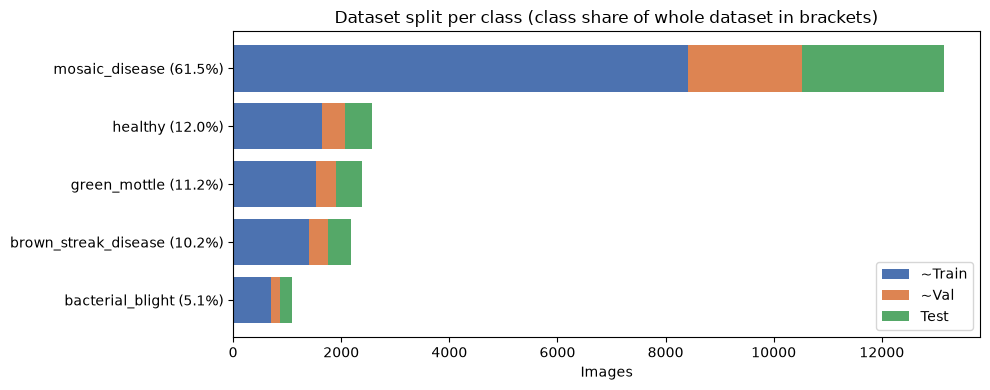

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPECTED_TOTAL = 21397

pool = count_images(DATA_DIR)
test = count_images(TEST_DIR)

split_df = pd.DataFrame({"Pool": pool, "Test": test}).fillna(0).astype(int)
split_df["~Train"] = (split_df["Pool"] * (1 - VALIDATION_SPLIT)).round().astype(int)
split_df["~Val"] = split_df["Pool"] - split_df["~Train"]
split_df["Total"] = split_df["Pool"] + split_df["Test"]
split_df["Class share %"] = (100 * split_df["Total"] / split_df["Total"].sum()).round(1)
split_df["Test share %"] = (100 * split_df["Test"] / split_df["Total"]).round(1)
split_df = split_df[["~Train", "~Val", "Test", "Total", "Class share %", "Test share %"]]
split_df.loc["ALL"] = [
    split_df["~Train"].sum(), split_df["~Val"].sum(), split_df["Test"].sum(),
    split_df["Total"].sum(), 100.0, round(100 * split_df["Test"].sum() / split_df["Total"].sum(), 1),
]
split_df = split_df.astype({c: int for c in ["~Train", "~Val", "Test", "Total"]})


# ---- Sanity checks -------------------------------------------------------
def _files(folder):
    return {(c, f) for c in count_images(folder) for f in os.listdir(os.path.join(folder, c))}

overlap = _files(DATA_DIR) & _files(TEST_DIR)
if overlap:
    raise RuntimeError(
        f"{len(overlap)} image(s) exist in BOTH {DATA_DIR} and {TEST_DIR} -> test leakage! "
        "Re-extract the zip into a clean data/ folder and delete the old test folder before splitting."
    )

total = int(split_df.loc["ALL", "Total"])
if abs(total - EXPECTED_TOTAL) > 0.01 * EXPECTED_TOTAL:
    print(f"WARNING: found {total:,} images but expected about {EXPECTED_TOTAL:,}. "
          "Was the dataset split twice or only partly copied?")
else:
    print(f"OK: {total:,} images in total (expected about {EXPECTED_TOTAL:,}); no train/test file overlap.")

majority = split_df.drop(index="ALL")["Class share %"].max()
majority_name = split_df.drop(index="ALL")["Class share %"].idxmax()
print(f"Majority-class baseline: always predicting '{majority_name}' would score about {majority:.1f}% accuracy.")

from IPython.display import display
display(split_df)

# ---- Chart: how each class is divided ------------------------------------
plot_df = split_df.drop(index="ALL")
fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(plot_df))
for col, color in zip(["~Train", "~Val", "Test"], ["#4C72B0", "#DD8452", "#55A868"]):
    ax.barh(plot_df.index, plot_df[col], left=left, label=col, color=color)
    left += plot_df[col].values
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels([f"{i.replace('Cassava___', '')} ({s}%)" for i, s in zip(plot_df.index, plot_df["Class share %"])])
ax.set_xlabel("Images")
ax.set_title("Dataset split per class (class share of whole dataset in brackets)")
ax.legend()
plt.tight_layout()
plt.show()

#### Housekeeping: stale caches
`.cache(filename)` silently **reuses cache files that already exist on disk**. After a new split, old cache files would
feed the model images that are now in the *test* set (leakage) and hide the new training data. A fresh split therefore
clears all cache files automatically; `clear_caches("resnet50")` can also free disk space (several GB per backbone) once a model is finished.

In [4]:
import glob

CACHE_DIR = "/home/alamin/cassava_classification"   # where the tf.data .cache() files are written

def clear_caches(tag=None):
    """Delete on-disk tf.data cache files (all backbones, or just one cache_tag)."""
    pattern = os.path.join(CACHE_DIR, f"cache_{tag}_*" if tag else "cache_*")
    files = glob.glob(pattern)
    for f in files:
        os.remove(f)
    print(f"Removed {len(files)} cache file(s) matching {pattern}")

# A fresh split invalidates every existing cache, so clear them automatically.
if split_performed:
    clear_caches()

### Image Processing
To input the data, we are going to use ```tf.keras.utils.image_dataset_from_directory```. This allows for easy processing of image data with options of augmentation and will take you from a directory of images on disk to a tf.data.Dataset in just a couple lines of code.

In [6]:
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

batch_size = 32
img_height = 256
img_width = 256


# Load Datasets directly into tf.data format
# Train/validation come from the data/ pool (VALIDATION_SPLIT is defined in the split cell);
# the test set is the separate folder created once by the split cell.
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    shuffle=False
)


Found 17120 files belonging to 5 classes.
Using 13696 files for training.
Found 17120 files belonging to 5 classes.
Using 3424 files for validation.
Found 4277 files belonging to 5 classes.


#### Data Visualization

['Cassava___bacterial_blight', 'Cassava___brown_streak_disease', 'Cassava___green_mottle', 'Cassava___healthy', 'Cassava___mosaic_disease']


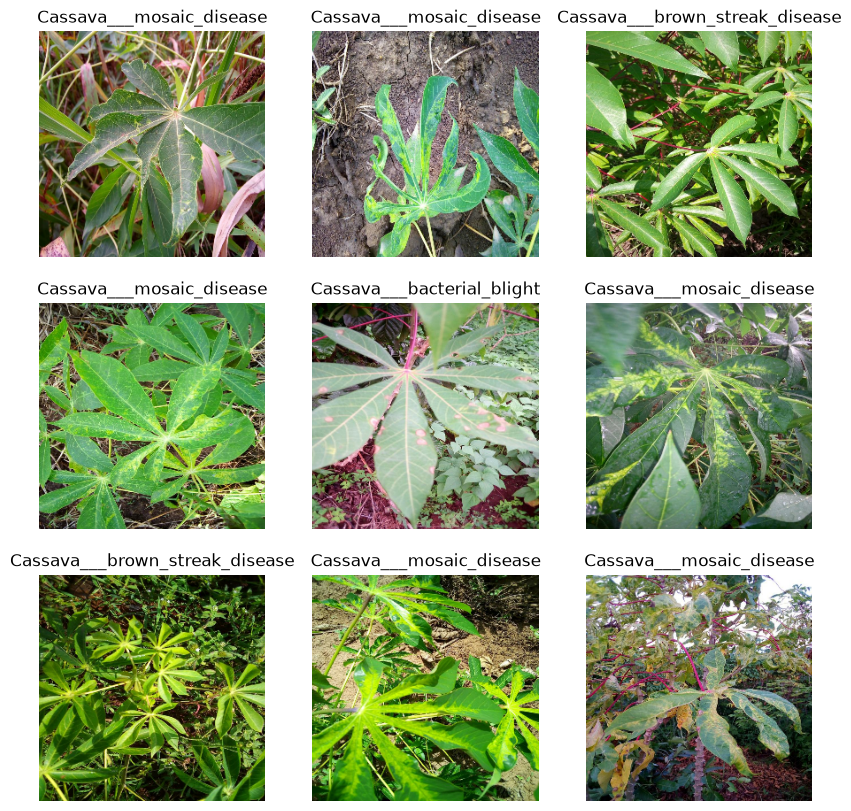

In [7]:
class_names = train_ds.class_names
print(class_names)

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")


In [8]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 256, 256, 3)
(32,)


In [9]:
from tensorflow.keras import layers

AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

# Light on-the-fly augmentation. Keras augmentation layers are automatically
# auto-disabled at inference time, so this is safe to leave inside the model.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

# Each backbone expects its own specific preprocessing (channel order,
# normalization range, etc.) - keep these mapped by name so the same
# pipeline code can be reused for ResNet50, EfficientNetB0, MobileNetV2.
PREPROCESS_FNS = {
    "resnet50": tf.keras.applications.resnet.preprocess_input,
    "efficientnetb0": tf.keras.applications.efficientnet.preprocess_input,
    "mobilenetv2": tf.keras.applications.mobilenet_v2.preprocess_input,
}

def make_preprocessed_datasets(preprocess_fn, cache_tag=None, prefetch_buffer=2):
    """Applies backbone-specific preprocessing to train/valid/test datasets.
    
    cache_tag: short string (e.g. "resnet50") used to build a unique cache
    file path per backbone, so caches don't collide with each other.
    prefetch_buffer: fixed buffer size instead of AUTOTUNE, since AUTOTUNE's
    unbounded buffering was what crashed earlier - a small fixed number still
    helps overlap preprocessing with training without blowing up RAM.
    """

    def _map(images, labels):
        return preprocess_fn(images), labels

    train = train_ds.map(_map, num_parallel_calls=AUTOTUNE)
    valid = valid_ds.map(_map, num_parallel_calls=AUTOTUNE)
    test = test_ds.map(_map, num_parallel_calls=AUTOTUNE)

    if cache_tag:
        cache_base = f"/home/alamin/cassava_classification/cache_{cache_tag}"
        train = train.cache(cache_base + "_train").prefetch(prefetch_buffer)
        valid = valid.cache(cache_base + "_valid").prefetch(prefetch_buffer)
    
    test = test.prefetch(prefetch_buffer)
    return train, valid, test

### Model building — reusable transfer-learning setup
Every backbone (ResNet50, EfficientNetB0, MobileNetV2) goes through the same two-phase
transfer-learning procedure, so this is written once as reusable functions rather than
copy-pasted per model:

- **Phase 1 (feature extraction):** the pretrained backbone is frozen, and only the new
  classifier head is trained. This keeps the random gradients from the freshly-initialized
  head from destroying the pretrained weights early on.
- **Phase 2 (fine-tuning):** once the head has converged, the backbone is unfrozen and
  trained further at a much lower learning rate, so the pretrained features can adapt
  slightly to cassava leaves specifically.

Both phases use `EarlyStopping` (so training runs until it actually stops improving,
not a fixed epoch count) and `ModelCheckpoint` (so the best-performing weights are saved,
not just whatever the last epoch happened to produce).

In [10]:
def build_transfer_model(backbone_fn, img_height, img_width, num_classes=NUM_CLASSES, augment=True):
    """Builds a transfer-learning model: pretrained backbone (frozen) + classifier head.

    backbone_fn: a callable like tf.keras.applications.ResNet50 /
                 EfficientNetB0 / MobileNetV2 that accepts include_top, weigths, input_shape and return a Model.
    Returns (model, backbone) - the backbone reference is needed later to unfreeze it for Phase 2 fine-tuning.    
    """
    backbone = backbone_fn(
        include_top=False,
        weights="imagenet",
        input_shape=(img_height, img_width, 3)
    )
    backbone.trainable = False # start frozen for phase 1

    # Define image input
    inputs = tf.keras.Input(shape=(img_height, img_width, 3))
    x = data_augmentation(inputs) if augment else inputs
    x = backbone(x)
    # avg. pools across the spatial dimensions (rows, columns) 
    # until it becomes ZeroDivisionError
    # Reshapes data into a 1D, allowing for proper input shpae into dense layers 
    # (8, 8, 2048) -> (2048)
    x = layers.GlobalAveragePooling2D()(x)
    # subtracts batch mean and divides by batch standard deviation
    # to reduce shift in input distributions between layers
    x = layers.BatchNormalization()(x)
    # dropout allows certain layers to be less dependent on certain feature, reduce overfitting
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(512, activation = 'relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    # output layer for all 5 classes
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    # construct model
    model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
    return model, backbone

In [11]:
def train_two_phase(model, backbone, train_ds, valid_ds,
                    phase1_epochs=30, phase2_epochs=15,
                    phase2_lr=1e-5, phase2_unfreeze_from_prefix=None,
                    patience=5, checkpoint_path="best_model.keras",
                    class_weight=None):
    """ Phase 1: train the classifier head only (backbone frozen).
        Phase 2: unfreeze (fully, or from a given layer index) and fine-tune
        at a low learning rate. Returns both training histories so they can be stitched together for plotting    
    """
    def make_callbacks():
        return [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=patience, restore_best_weights=True
            ),
            tf.keras.callbacks.ModelCheckpoint(
                checkpoint_path, monitor="val_loss", save_best_only=True
            ),
        ]

    # compile the model - we,re training using the Adam Optimizer
    # and tf.keras.losses.SparseCategoricalCrossentropy loss function. 
    model.compile(
        optimizer="adam",
        loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=['accuracy']
    )
    # model structure
    print("==== Phase 1: training classifier head (backbone frozen) ====")
    history1 = model.fit(
        train_ds, validation_data=valid_ds,
        epochs=phase1_epochs, callbacks=make_callbacks(),
        class_weight=class_weight, 
    )

    # Phase 2: unfreeze and fine-tune at a low learning rate
    backbone.trainable = True
    if phase2_unfreeze_from_prefix is not None:
        names = [l.name for l in backbone.layers]
        matches = [i for i, n in enumerate(names) if n.startswith(phase2_unfreeze_from_prefix)]
        if not matches:
            raise ValueError(
                f"No backcone layer starts with '{phase2_unfreeze_from_prefix}'. "
                f"Some layer names to choose from: {names[::max(1, len(names) // 15)]}"
            )
        start = matches[0]
        for layer in backbone.layers[:start]:
            layer.trainable=False
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable=False

    n_trainable = sum(tf.size(w).numpy() for w in backbone.trainable_weights)
    print(f"Backbone trainable parameters in Phase 2: {n_trainable:,}")
    
    import gc; tf.keras.backend.clear_session(); gc.collect()
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=phase2_lr),
        loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=['accuracy'],
    )
    print("==== Phase 2: fine-tuning unfrozen backbone (low learning rate) ====")
    history2 = model.fit(
        train_ds, validation_data=valid_ds,
        epochs=phase2_epochs, callbacks=make_callbacks(),
        class_weight=class_weight
    )

    return history1, history2

In [12]:
def plot_history(history1, history2=None, title=""):
    """Plots accuracy/loss curves, stitching Phase 1 and Phase 2 together
    with a marker showing where fine-tuning started."""
    acc = list(history1.history["accuracy"])
    val_acc = list(history1.history["val_accuracy"])
    loss = list(history1.history["loss"])
    val_loss = list(history1.history["val_loss"])

    phase2_start = None
    if history2 is not None:
        phase2_start = len(acc)
        acc += history2.history["accuracy"]
        val_acc += history2.history["val_accuracy"]
        loss += history2.history["loss"]
        val_loss += history2.history["val_loss"]

    epochs_range = range(len(acc))

    plt.figure(figsize=(10, 8))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label="Training Accuracy")
    plt.plot(epochs_range, val_acc, label="Validation Accuracy")
    if phase2_start:
        plt.axvline(phase2_start - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
    plt.legend(loc="lower right")
    plt.title(f"{title} - Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label="Training Loss")
    plt.plot(epochs_range, val_loss, label="Validation Loss")
    if phase2_start:
        plt.axvline(phase2_start - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
    plt.legend(loc="upper right")
    plt.title(f"{title} - Loss")
    plt.tight_layout()
    plt.show()

### Evaluation helpers
`evaluate_model()` runs a Keras model over the test set once and reports: overall accuracy, **macro-F1** (every disease counts
equally), balanced accuracy, a **per-disease table** (accuracy/recall, precision, F1, what each disease is most often confused with),
and confusion matrices. The underlying `evaluate_predictions()` takes plain label arrays, so the classical-ML baselines can be
scored with exactly the same metrics later. Results and figures are saved in `results/`.

In [13]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
RESULTS = {} # model name -> metrics; filled by evaluate_*(), read by compare_models()

def pretty_name(c):
    return c.replace("Cassava___", "").replace("_", " ")

def _plot_matrix(ax, matrix, labels, title, fmt):
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    thresh = matrix.max() / 2
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center",
                    color="white" if matrix[i, j] > thresh else "black")

def evaluate_predictions(y_true, y_pred, model_name, y_prob=None, params=None,
                         labels=None, show_plots=True):
    """Full classification report for any model (CNN or classical ML):
    overall accuracy, macro-F1, balanced accuracy, per-disease accuracy/precision/F1,
    confusion matrices and what each class is most often mistaken for."""
    labels = labels or [pretty_name(c) for c in class_names]
    k = len(labels)
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(k)))
    support = cm.sum(axis=1)
    correct = np.diag(cm)
    per_class_acc = np.divide(correct, support, out=np.zeros(k), where=support > 0) # = per-class recall
    precision, _, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(k)), zero_division=0
    )

    accuracy = correct.sum() / cm.sum()
    macro_f1 = float(f1.mean()) # every class counts equally
    weighted_f1 = float(np.average(f1, weights=support)) # classes weighted by size
    balanced_acc = float(per_class_acc.mean()) # mean per-class recall
    baseline = support.max() / support.sum()             # majority-class guess
    loss = None
    if y_prob is not None:
        p = np.clip(np.asarray(y_prob)[np.arange(len(y_true)), y_true])
        loss = float(-np.log(p).mean())

    rows = []
    for i in range(k):
        off = cm[i].copy()
        off[i] = 0
        if off.sum() > 0:
            j = int(off.argmax())
            confused = f"{labels[j]} ({off[j] / support[i]:.0%} of its mages)"
        else:
            confused = "-"
        rows.append({
            "Disease class": labels[i], 
            "Test images": int(support[i]), 
            "Correct": int(correct[i]), 
            "Accuracy (recall)": per_class_acc[i],
            "Precision": precision[i],
            "F1": f1[i],
            "Most confused with": confused
        })
    per_class = pd.DataFrame(rows).set_index("Disease class")
    
    print(f"=== {model_name} on {len(y_true):,} test images ===")
    print(f"Accuracy: {accuracy:.2%} | Macro-F1: {macro_f1:.4f} | Weighted-F1: {weighted_f1:.4f} | "
          f"Balanced accuracy: {balanced_acc:.2%}" + (f" | Loss: {loss:.4f}" if loss is not None else ""))
    print(f"Majority-class baseline: {baseline:.2%}  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)")
    shown = per_class.copy()
    for col in ["Accuracy (recall)", "Precision", "F1"]:
        shown[col] = (shown[col] * 100).round(1).astype(str) + "%"
    display(shown)

    if show_plots:
        fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
        _plot_matrix(axes[0], cm, labels, f"{model_name} - confusion matrix (counts)", "d")
        _plot_matrix(axes[1], cm / np.maximum(support[:, None], 1), labels,
                     f"{model_name} - row-normalised (diagonal = per-class accuracy)", ".2f")
        bars = axes[2].bar(labels, per_class_acc * 100, color="#4C72B0")
        axes[2].axhline(accuracy * 100, color="red", linestyle="--", label=f"Overall accuracy {accuracy:.1%}")
        axes[2].axhline(baseline * 100, color="gray", linestyle=":", label=f"Majority baseline {baseline:.1%}")
        for b, v in zip(bars, per_class_acc * 100):
            axes[2].text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center")
        axes[2].set_ylim(0, 110)
        axes[2].set_ylabel("Accuracy on that disease (%)")
        axes[2].set_title(f"{model_name} - accuracy per disease")
        axes[2].set_xticks(range(k))
        axes[2].set_xticklabels(labels, rotation=35, ha="right")
        axes[2].legend(loc="lower right")
        plt.tight_layout()
        fig.savefig(os.path.join(RESULTS_DIR, f"{model_name}_evaluation.png"), dpi=200, bbox_inches="tight")
        plt.show()

    result = {
        "accuracy": float(accuracy), "macro_f1": macro_f1, "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc, "loss": loss, "params": params,
        "fp32_size_mb": (params * 4 / 1e6) if params else None,
        "per_class_accuracy": {l: float(v) for l, v in zip(labels, per_class_acc)},
        "per_class_f1": {l: float(v) for l, v in zip(labels, f1)},
        "confusion_matrix": cm.tolist(),
    }
    RESULTS[model_name] = result
    with open(os.path.join(RESULTS_DIR, f"{model_name}_results.json"), "w") as f:
        json.dump(result, f, indent=2)   # survives kernel restarts / WSL2 crashes
    return result

def evaluate_model(model, test_data, model_name, show_plots=True):
    """Runs a Keras model once over the (un-shuffled) test set, then reports everything."""
    y_true, y_prob = [], []
    for x, y in test_data:
        y_prob.append(np.asarray(model.predict_on_batch(x)))
        y_true.append(np.asarray(y))
    y_prob = np.concatenate(y_prob)
    y_true = np.concatenate(y_true)
    return evaluate_predictions(y_true, y_prob.argmax(axis=1), model_name, y_prob=y_prob,
                                params=model.count_params(), show_plots=show_plots)

def compare_models():
    """Side-by-side table + per-disease chart for every model evaluated so far."""
    for fn in sorted(os.listdir(RESULTS_DIR)):          # reload anything saved before a restart
        if fn.endswith("_results.json"):
            name = fn[:-len("_results.json")]
            if name not in RESULTS:
                RESULTS[name] = json.load(open(os.path.join(RESULTS_DIR, fn)))
    if not RESULTS:
        print("No results yet - run evaluate_model() first.")
        return
    summary = pd.DataFrame({
        name: {"Accuracy %": r["accuracy"] * 100, "Macro-F1": r["macro_f1"],
               "Balanced acc %": r["balanced_accuracy"] * 100, "Test loss": r["loss"],
               "Params (M)": (r["params"] / 1e6) if r["params"] else None,
               "FP32 size (MB)": r["fp32_size_mb"]}
        for name, r in RESULTS.items()}).T.round(3)
    per_class = pd.DataFrame({n: r["per_class_accuracy"] for n, r in RESULTS.items()}).T * 100
    display(summary)
    display(per_class.round(1).rename_axis("Accuracy % per disease"))
    ax = per_class.T.plot(kind="bar", figsize=(11, 5), rot=25)
    ax.set_ylabel("Accuracy on that disease (%)")
    ax.set_title("Per-disease test accuracy by model")
    ax.set_ylim(0, 105)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "model_comparison_per_class.png"), dpi=200, bbox_inches="tight")
    plt.show()




In [14]:
TRAIN_CFG = dict(phase1_epochs=30, phase2_epochs=15, phase2_lr=1e-5, patience=5)

### ResNet50
Applying the reusable pipeline above to ResNet50.

In [47]:
train_ds_r, valid_ds_r, test_ds_r = make_preprocessed_datasets(
    PREPROCESS_FNS["resnet50"], cache_tag="resnet50", prefetch_buffer=2
)

In [48]:
r_model, r_backbone = build_transfer_model(
    tf.keras.applications.ResNet50, img_height, img_width
)
r_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,649,605 (94.03 MB)

 Trainable params: 1,056,773 (4.03 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

In [49]:
r_history1, r_history2 = train_two_phase(
    r_model, r_backbone, train_ds_r, valid_ds_r,
    phase2_unfreeze_from_prefix="conv5_block1", 
    checkpoint_path="resnet50_best.keras", **TRAIN_CFG
)

==== Phase 1: training classifier head (backbone frozen) ====
Epoch 1/30


/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - accuracy: 0.6105 - loss: 1.2669

W0000 00:00:1792015377.656367   60677 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 442s 1s/step - accuracy: 0.6105 - loss: 1.2669 - val_accuracy: 0.6963 - val_loss: 0.8242
Epoch 2/30


W0000 00:00:1792015378.469442   60677 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 450s 1s/step - accuracy: 0.6860 - loss: 0.8739 - val_accuracy: 0.7109 - val_loss: 0.7936
Epoch 3/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 470s 1s/step - accuracy: 0.7082 - loss: 0.8097 - val_accuracy: 0.7231 - val_loss: 0.7589
Epoch 4/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 470s 1s/step - accuracy: 0.7139 - loss: 0.7807 - val_accuracy: 0.7293 - val_loss: 0.7445
Epoch 5/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 561s 1s/step - accuracy: 0.7180 - loss: 0.7699 - val_accuracy: 0.7284 - val_loss: 0.7382
Epoch 6/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 469s 1s/step - accuracy: 0.7277 - loss: 0.7509 - val_accuracy: 0.7369 - val_loss: 0.7295
Epoch 7/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 475s 1s/step - accuracy: 0.7286 - loss: 0.7407 - val_accuracy: 0.7453 - val_loss: 0.7160
Epoch 8/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 476s 1s/step - accuracy: 0.7290 - loss: 0.7384 - val_accuracy: 0.7293 - val_loss: 0.7452
Epoch 9/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 536s 1s/step - accuracy: 0.7336 - loss: 0.7227 - val_accuracy: 0.729

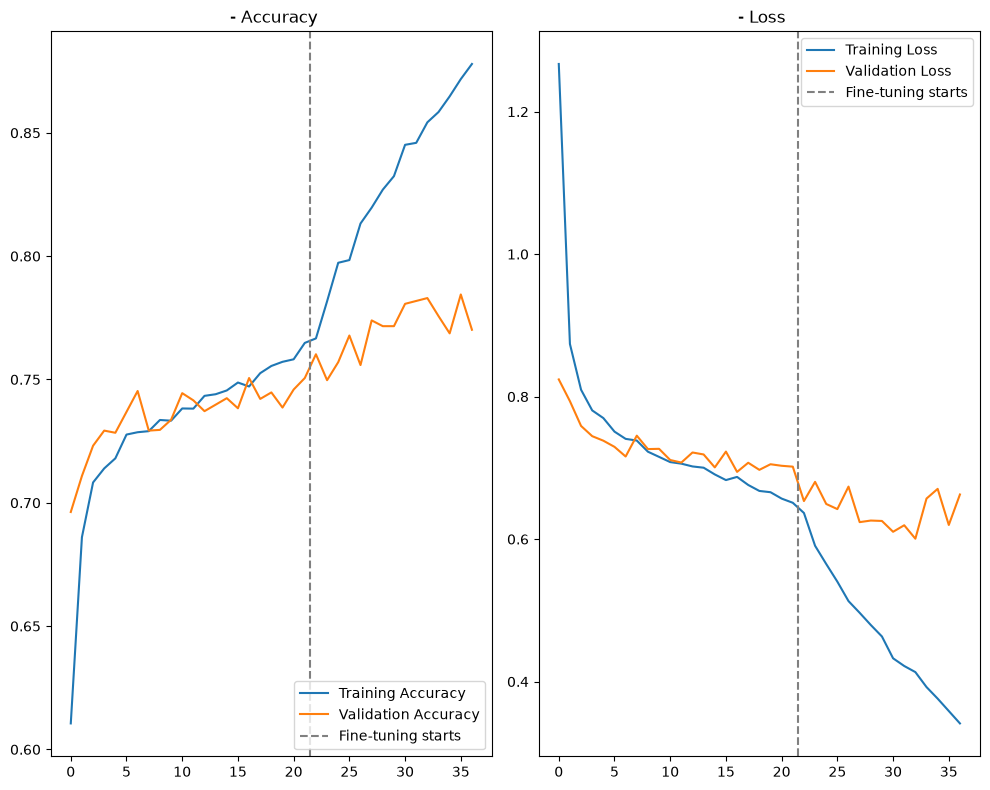

In [50]:
plot_history(r_history1, r_history2)

=== ResNet50 on 4,277 test images ===
Accuracy: 79.28% | Macro-F1: 0.6389 | Weighted-F1: 0.7910 | Balanced accuracy: 63.09% | Loss: 0.6074
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,74,34.1%,59.2%,43.3%,healthy (40% of its mages)
brown streak disease,437,290,66.4%,59.8%,62.9%,healthy (21% of its mages)
green mottle,477,252,52.8%,73.3%,61.4%,mosaic disease (28% of its mages)
healthy,515,363,70.5%,52.5%,60.2%,brown streak disease (12% of its mages)
mosaic disease,2631,2412,91.7%,91.6%,91.7%,healthy (3% of its mages)


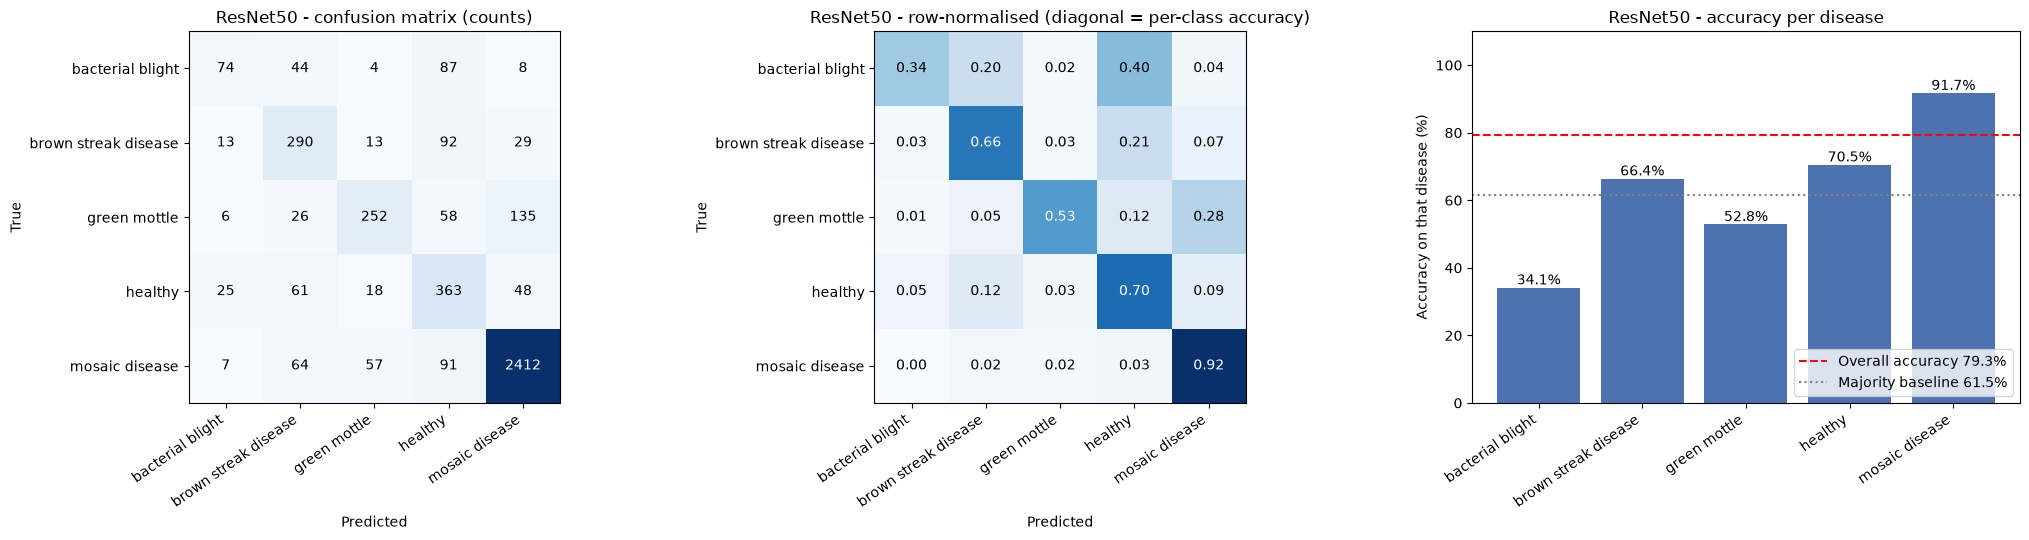

Removed 4 cache file(s) matching /home/alamin/cassava_classification/cache_resnet50_*


In [55]:
evaluate_model(r_model, test_ds_r, "ResNet50")
clear_caches("resnet50")   # optional: frees several GB of disk once this model is finished

### EfficientNetB0
EfficientNetB0 has its own rescaling/normalisation layers built in, so its `preprocess_input` passes pixels through unchanged - that is correct, not a missing step. Phase 2 unfreezes from `block6a` (the last two stages); if memory allows you can try `block5a`, and if it crashes try `block7a`.

In [15]:
train_ds_e, valid_ds_e, test_ds_e = make_preprocessed_datasets(
    PREPROCESS_FNS["efficientnetb0"], cache_tag="efficientnetb0", prefetch_buffer=2
)

In [16]:
e_model, e_backbone = build_transfer_model(
    tf.keras.applications.EfficientNetB0, img_height, img_width
)
e_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,715,176 (17.99 MB)

 Trainable params: 662,021 (2.53 MB)

 Non-trainable params: 4,053,155 (15.46 MB)

In [18]:
e_history1, e_history2 = train_two_phase(
    e_model, e_backbone, train_ds_e, valid_ds_e, 
    phase2_unfreeze_from_prefix="block6a",
    checkpoint_path="effnetb0_best.keras", **TRAIN_CFG
)

==== Phase 1: training classifier head (backbone frozen) ====
Epoch 1/30


/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


428/428 ━━━━━━━━━━━━━━━━━━━━ 194s 440ms/step - accuracy: 0.6151 - loss: 1.2441 - val_accuracy: 0.7313 - val_loss: 0.7633
Epoch 2/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 197s 459ms/step - accuracy: 0.6871 - loss: 0.8857 - val_accuracy: 0.7144 - val_loss: 0.8007
Epoch 3/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 370s 866ms/step - accuracy: 0.7055 - loss: 0.8071 - val_accuracy: 0.7158 - val_loss: 0.8045
Epoch 4/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 429s 1s/step - accuracy: 0.7177 - loss: 0.7802 - val_accuracy: 0.7331 - val_loss: 0.7362
Epoch 5/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 204s 476ms/step - accuracy: 0.7188 - loss: 0.7663 - val_accuracy: 0.7301 - val_loss: 0.7507
Epoch 6/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 379s 887ms/step - accuracy: 0.7207 - loss: 0.7586 - val_accuracy: 0.7211 - val_loss: 0.7492
Epoch 7/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 427s 999ms/step - accuracy: 0.7261 - loss: 0.7396 - val_accuracy: 0.7348 - val_loss: 0.7141
Epoch 8/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 202s 472ms/step - accuracy: 0.7265 - loss: 0.7465 

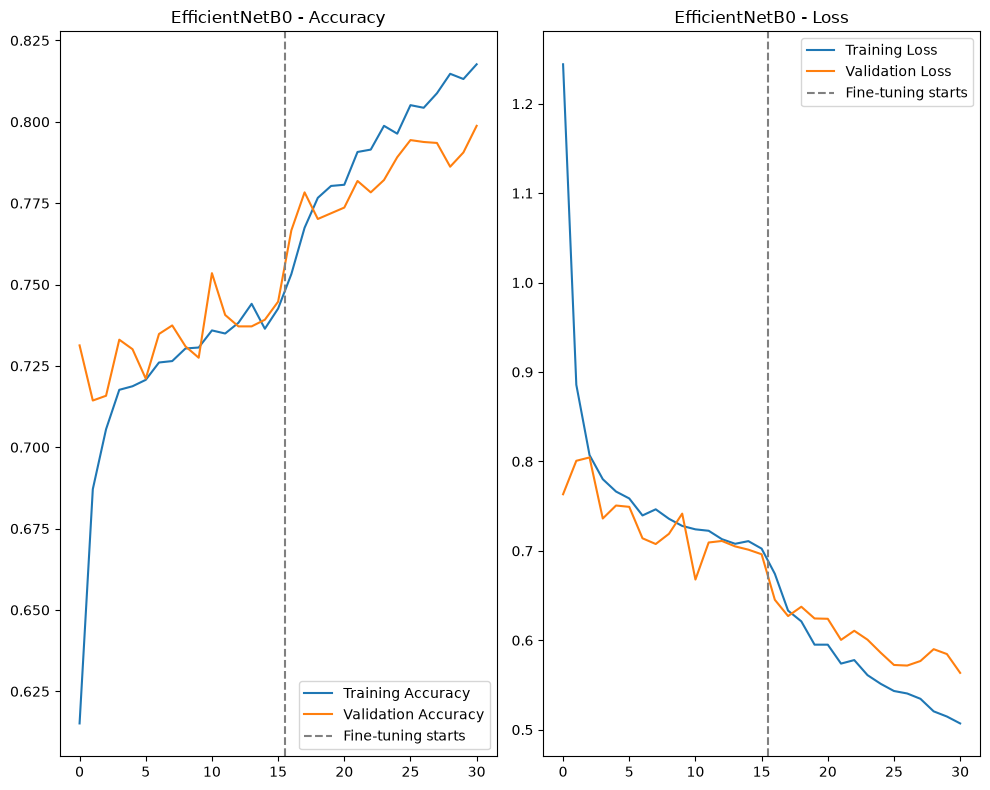

In [19]:
plot_history(e_history1, e_history2, title="EfficientNetB0")

=== EfficientNetB0 on 4,277 test images ===
Accuracy: 79.82% | Macro-F1: 0.6579 | Weighted-F1: 0.7978 | Balanced accuracy: 65.77% | Loss: 0.5784
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,125,57.6%,52.7%,55.1%,healthy (31% of its mages)
brown streak disease,437,231,52.9%,67.5%,59.3%,healthy (28% of its mages)
green mottle,477,225,47.2%,84.3%,60.5%,mosaic disease (27% of its mages)
healthy,515,407,79.0%,50.8%,61.9%,bacterial blight (8% of its mages)
mosaic disease,2631,2426,92.2%,92.2%,92.2%,healthy (4% of its mages)


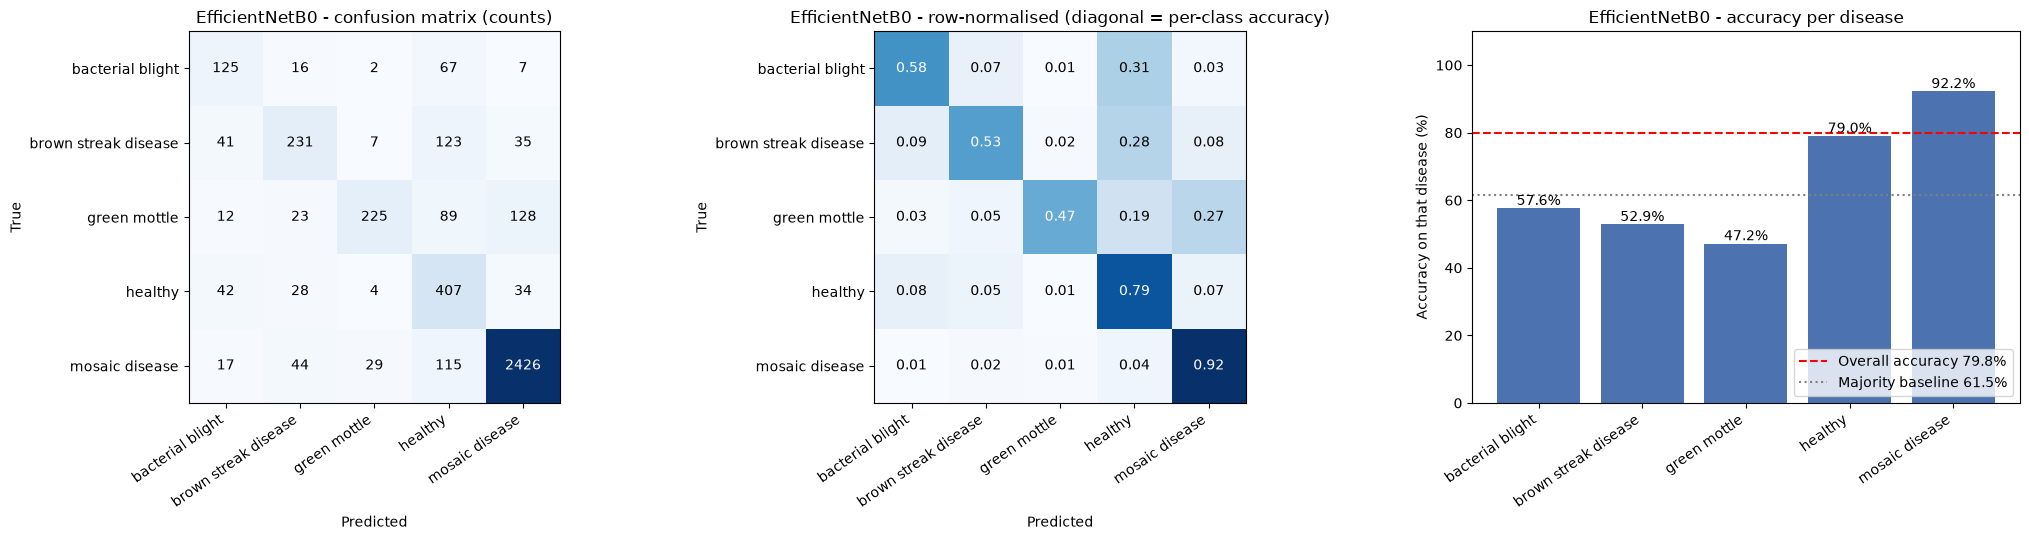

Removed 4 cache file(s) matching /home/alamin/cassava_classification/cache_efficientnetb0_*


In [20]:
evaluate_model(e_model, test_ds_e, "EfficientNetB0")
clear_caches("efficientnetb0")

### MobileNetV2
Keras prints a warning that weights for 224x224 input are loaded when the input size is 256x256 - this is expected and harmless (the convolution weights do not depend on input size). Phase 2 unfreezes from `block_13` (the last four inverted-residual blocks).

In [21]:
train_ds_m, valid_ds_m, test_ds_m = make_preprocessed_datasets(
    PREPROCESS_FNS["mobilenetv2"], cache_tag="mobilenetv2", prefetch_buffer=2
)

In [22]:
m_model, m_backbone = build_transfer_model(
    tf.keras.applications.MobileNetV2, img_height, img_width
)
m_model.summary()

/tmp/ipykernel_5777/1307496241.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = backbone_fn(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,923,589 (11.15 MB)

 Trainable params: 662,021 (2.53 MB)

 Non-trainable params: 2,261,568 (8.63 MB)

In [23]:
m_history1, m_history2 = train_two_phase(
    m_model, m_backbone, train_ds_m, valid_ds_m,
    phase2_unfreeze_from_prefix="block_13",
    checkpoint_path="mobilenetv2_best.keras", **TRAIN_CFG,
)

==== Phase 1: training classifier head (backbone frozen) ====
Epoch 1/30


/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.5960 - loss: 1.2821

W0000 00:00:1792059030.252743    5777 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 154s 342ms/step - accuracy: 0.5960 - loss: 1.2821 - val_accuracy: 0.6989 - val_loss: 0.8199
Epoch 2/30


W0000 00:00:1792059030.772128    5777 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 142s 332ms/step - accuracy: 0.6820 - loss: 0.8832 - val_accuracy: 0.7132 - val_loss: 0.7982
Epoch 3/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 145s 338ms/step - accuracy: 0.7052 - loss: 0.8253 - val_accuracy: 0.7030 - val_loss: 0.7843
Epoch 4/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 199s 331ms/step - accuracy: 0.7065 - loss: 0.8036 - val_accuracy: 0.7088 - val_loss: 0.7838
Epoch 5/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 147s 343ms/step - accuracy: 0.7117 - loss: 0.7922 - val_accuracy: 0.7234 - val_loss: 0.7482
Epoch 6/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 146s 342ms/step - accuracy: 0.7113 - loss: 0.7790 - val_accuracy: 0.7079 - val_loss: 0.7780
Epoch 7/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 163s 381ms/step - accuracy: 0.7180 - loss: 0.7727 - val_accuracy: 0.7234 - val_loss: 0.7610
Epoch 8/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 298s 696ms/step - accuracy: 0.7198 - loss: 0.7618 - val_accuracy: 0.7047 - val_loss: 0.7834
Epoch 9/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 225s 526ms/step - accuracy: 0.7223 - loss: 0.75

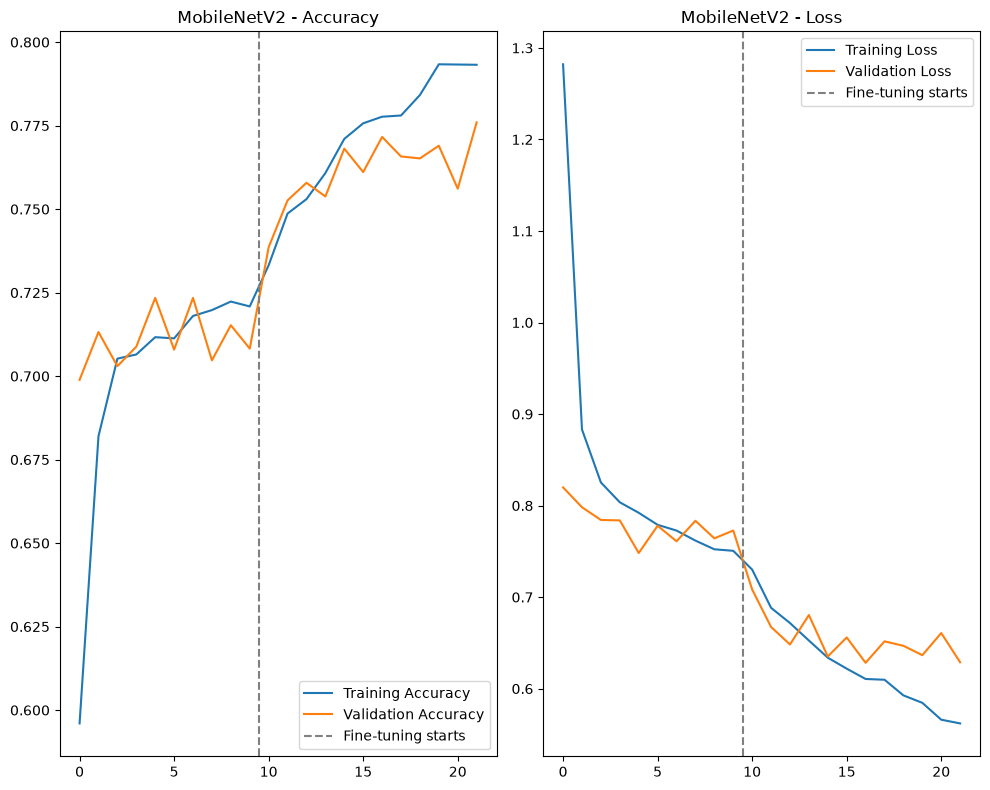

In [24]:
plot_history(m_history1, m_history2, title="MobileNetV2")

=== MobileNetV2 on 4,277 test images ===
Accuracy: 77.34% | Macro-F1: 0.6213 | Weighted-F1: 0.7728 | Balanced accuracy: 61.65% | Loss: 0.6413
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,83,38.2%,58.5%,46.2%,healthy (37% of its mages)
brown streak disease,437,250,57.2%,58.7%,57.9%,healthy (21% of its mages)
green mottle,477,229,48.0%,67.6%,56.1%,mosaic disease (29% of its mages)
healthy,515,387,75.1%,50.1%,60.1%,brown streak disease (10% of its mages)
mosaic disease,2631,2359,89.7%,90.8%,90.2%,healthy (5% of its mages)


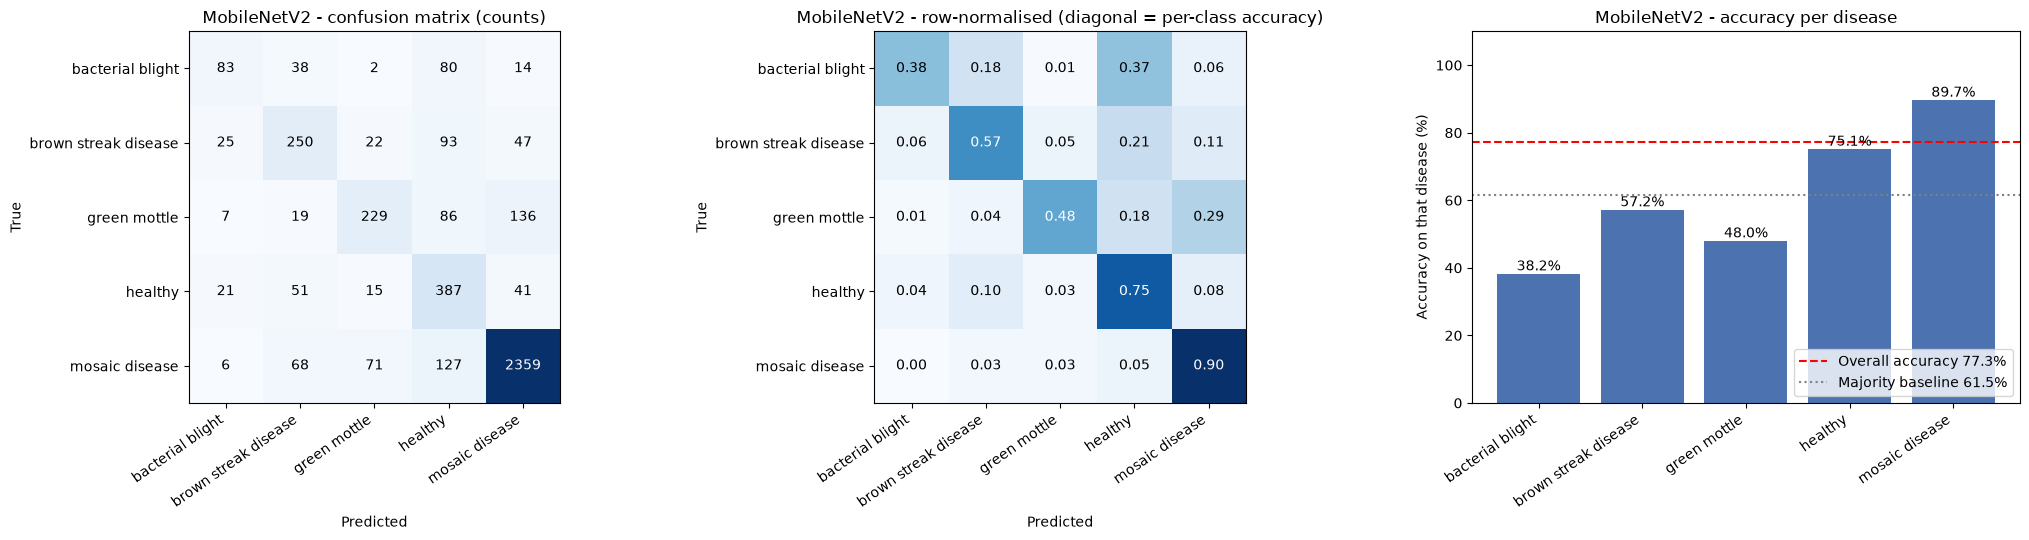

Removed 4 cache file(s) matching /home/alamin/cassava_classification/cache_mobilenetv2_*


In [25]:
evaluate_model(m_model, test_ds_m, "MobileNetV2")
clear_caches("mobilenetv2")

### Model comparison
Side-by-side metrics and per-disease accuracy for every model evaluated so far (also reloads saved results after a restart).

,Accuracy %,Macro-F1,Balanced acc %,Test loss,Params (M),FP32 size (MB)
EfficientNetB0,79.822,0.658,65.774,0.578,4.715,18.861
MobileNetV2,77.344,0.621,61.655,0.641,2.924,11.694
ResNet50,79.285,0.639,63.091,0.607,24.650,98.598


,bacterial blight,brown streak disease,green mottle,healthy,mosaic disease
Accuracy % per disease,,,,,
EfficientNetB0,57.6,52.9,47.2,79.0,92.2
MobileNetV2,38.2,57.2,48.0,75.1,89.7
ResNet50,34.1,66.4,52.8,70.5,91.7


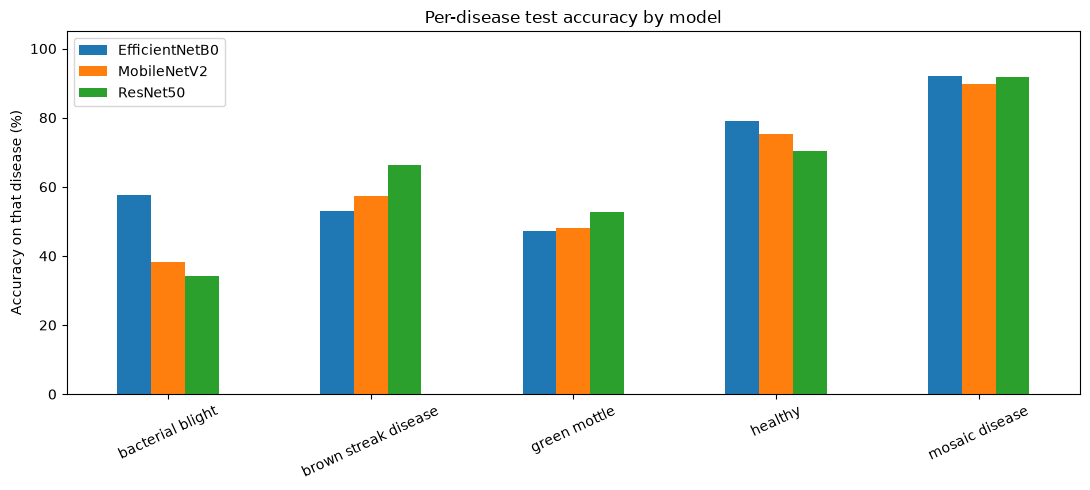

In [26]:
compare_models()

### EfficientNetB0 — class-weighted variant
The original ResNet50, EfficientNetB0 and MobileNetV2 runs remain unweighted. This additional EfficientNetB0 run uses inverse-frequency class weights computed from the training split only, to give the minority classes a larger contribution to the training loss. It is evaluated separately so its results can be compared fairly with the unweighted models.

In [16]:
from sklearn.utils.class_weight import compute_class_weight

# Build weights from the actual training labels, not validation/test labels.
# image_dataset_from_directory selects validation files from the beginning of
# its sorted file list; training uses the remainder (then shuffles it).
_pool_paths = []
_pool_labels = []
_pool_labels_train = []
val_pool_paths, val_pool_labels = [], []
train_pool_path, train_pool_labels = [], []
for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    class_paths = sorted(
        os.path.join(class_dir, f) for f in os.listdir(class_dir)
        if f.lower().endswith(IMG_EXTS)
    )
    _pool_paths.extend(class_paths)
    _pool_labels.extend([class_idx] * len(class_paths))
    val_split = int(len(class_paths)*VALIDATION_SPLIT)
    val_pool_paths.extend(class_paths[:val_split])
    val_pool_labels.extend([class_idx] * len(class_paths[:val_split]))
    train_pool_path.extend(class_paths[val_split:])
    train_pool_labels.extend([class_idx] * len(class_paths[val_split:]))
    _pool_labels_train.extend([class_idx] * (len(class_paths)-val_split))

_num_val = int(len(_pool_paths) * VALIDATION_SPLIT)
_train_labels_for_weights = np.asarray(_pool_labels_train, dtype=np.int64)
_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=_train_labels_for_weights,
)
EFFNET_CLASS_WEIGHT = {i: float(w) for i, w in enumerate(_weight_values)}
print("EfficientNetB0 class weights (class index -> weight):")
print({class_names[i]: round(w, 4) for i, w in EFFNET_CLASS_WEIGHT.items()})

EfficientNetB0 class weights (class index -> weight):
{'Cassava___bacterial_blight': 3.9362, 'Cassava___brown_streak_disease': 1.9541, 'Cassava___green_mottle': 1.7929, 'Cassava___healthy': 1.6604, 'Cassava___mosaic_disease': 0.3253}


In [39]:
# Rebuild the same architecture and preprocessing pipeline; keep the original
# unweighted EfficientNetB0 model/checkpoint untouched.
ew_model, ew_backbone = build_transfer_model(
    tf.keras.applications.EfficientNetB0, img_height, img_width
)
ew_history1, ew_history2 = train_two_phase(
    ew_model, ew_backbone, train_ds_e, valid_ds_e,
    phase2_unfreeze_from_prefix="block6a",
    checkpoint_path="effnetb0_weighted_best.keras",
    class_weight=EFFNET_CLASS_WEIGHT, **TRAIN_CFG
)

==== Phase 1: training classifier head (backbone frozen) ====
Epoch 1/30


/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.4934 - loss: 1.7082

W0000 00:00:1792193250.655370    5777 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 216s 472ms/step - accuracy: 0.4934 - loss: 1.7082 - val_accuracy: 0.5447 - val_loss: 1.3132
Epoch 2/30


W0000 00:00:1792193251.653994    5777 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


428/428 ━━━━━━━━━━━━━━━━━━━━ 192s 449ms/step - accuracy: 0.5730 - loss: 1.2539 - val_accuracy: 0.5394 - val_loss: 1.2688
Epoch 3/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 193s 451ms/step - accuracy: 0.5932 - loss: 1.1647 - val_accuracy: 0.5429 - val_loss: 1.2381
Epoch 4/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 195s 457ms/step - accuracy: 0.6057 - loss: 1.1219 - val_accuracy: 0.5453 - val_loss: 1.2241
Epoch 5/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 202s 472ms/step - accuracy: 0.6161 - loss: 1.0804 - val_accuracy: 0.5745 - val_loss: 1.1620
Epoch 6/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 204s 476ms/step - accuracy: 0.6141 - loss: 1.0935 - val_accuracy: 0.5581 - val_loss: 1.1763
Epoch 7/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 206s 481ms/step - accuracy: 0.6146 - loss: 1.0856 - val_accuracy: 0.5733 - val_loss: 1.1469
Epoch 8/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 204s 477ms/step - accuracy: 0.6195 - loss: 1.0659 - val_accuracy: 0.5619 - val_loss: 1.1476
Epoch 9/30
428/428 ━━━━━━━━━━━━━━━━━━━━ 206s 482ms/step - accuracy: 0.6232 - loss: 1.05

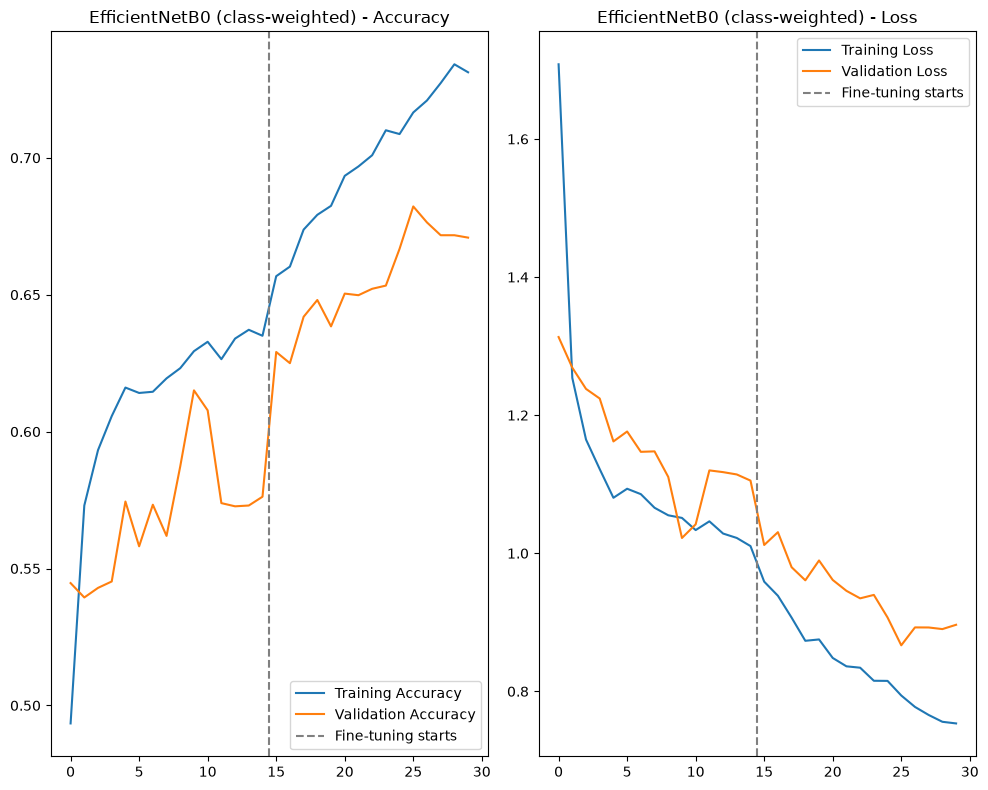

In [40]:
plot_history(ew_history1, ew_history2, title="EfficientNetB0 (class-weighted)")

=== EfficientNetB0_weighted on 4,277 test images ===
Accuracy: 69.79% | Macro-F1: 0.6009 | Weighted-F1: 0.7207 | Balanced accuracy: 67.79% | Loss: 0.8707
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,158,72.8%,38.6%,50.5%,healthy (18% of its mages)
brown streak disease,437,245,56.1%,49.2%,52.4%,healthy (24% of its mages)
green mottle,477,302,63.3%,56.7%,59.8%,healthy (15% of its mages)
healthy,515,385,74.8%,43.6%,55.1%,bacterial blight (15% of its mages)
mosaic disease,2631,1895,72.0%,97.0%,82.7%,healthy (11% of its mages)


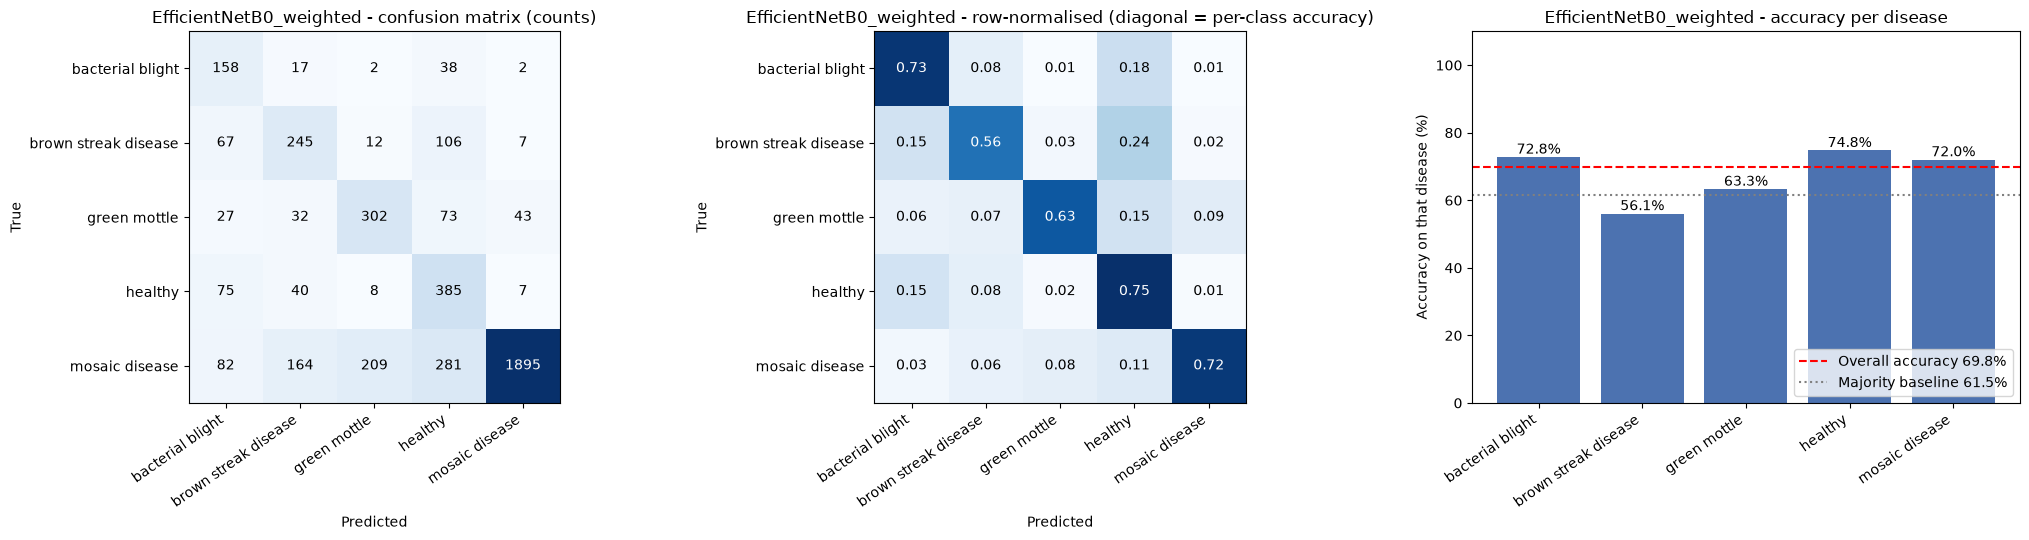

Removed 4 cache file(s) matching /home/alamin/cassava_classification/cache_efficientnetb0_*


In [42]:
evaluate_model(ew_model, test_ds_e, "EfficientNetB0_weighted")
clear_caches("efficientnetb0")

### Export manifests and per-image predictions

Run this cell after training. It writes a CSV manifest for every image and its train/validation/test assignment, then loads each saved best checkpoint and writes test-set per-image predictions (true class, predicted class, confidence, and per-class probabilities). The prediction CSVs are intended for downstream error analysis and classical-model comparisons.

In [17]:
from dataclasses import field
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow
import os

EXPORT_DIR = "artifacts"
MANIFEST_DIR = os.path.join(EXPORT_DIR, "manifest")
PREDICTION_DIR = os.path.join(EXPORT_DIR, "predictions")
os.makedirs(MANIFEST_DIR, exist_ok=True)
os.makedirs(PREDICTION_DIR, exist_ok=True)

# Reconstruct the same deterministic file assignment used by
# image_dataset_from_directory(validation_split=..., subset=...):
# sorted paths; the first floor(N * validation_split) go to validation.
manifest_rows = []

for i, (path, labels) in enumerate(zip(_pool_paths, _pool_labels)):
    manifest_rows.append({
        "filepath": os.path.abspath(path),
        "relative_path": os.path.relpath(path, "."),
        "split": "validation" if path in val_pool_paths else "train",
        "class_index": int(labels),
        "class_name": class_names[labels],
    })

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(TEST_DIR, class_name)
    if not os.path.isdir(class_dir):
        continue
    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(IMG_EXTS):
            path = os.path.join(class_dir, filename)
            manifest_rows.append({
                "filepath": os.path.abspath(path),
                "relative_path": os.path.relpath(path, "."), 
                "split": "test",
                "class_index": int(class_idx),
                "class_name": class_name,
            })

manifest_df = pd.DataFrame(manifest_rows)
manifest_path = os.path.join(MANIFEST_DIR, "image_manifest.csv")
manifest_df.to_csv(manifest_path, index=False)

for split_name in ("train", "validation", "test"):
    manifest_df.loc[manifest_df["split"] == split_name].to_csv(os.path.join(MANIFEST_DIR, f"{split_name}_manifest.csv"), index=False)

print(f"Saved {len(manifest_df):,} image records to {manifest_path}")
print(manifest_df.groupby(["split", "class_name"]).size().unstack(fill_value=0))


Saved 21,397 image records to artifacts/manifest/image_manifest.csv
class_name  Cassava___bacterial_blight  Cassava___brown_streak_disease  \
split                                                                    
test                               217                             437   
train                              696                            1402   
validation                         174                             350   

class_name  Cassava___green_mottle  Cassava___healthy  \
split                                                   
test                           477                515   
train                         1528               1650   
validation                     381                412   

class_name  Cassava___mosaic_disease  
split                                 
test                            2631  
train                           8422  
validation                      2105  


In [51]:
# Build a deterministic test dataset from the manifest so each prediction
# row can be joined back to its exact source image.
test_manifest = manifest_df.loc[manifest_df["split"] == "test"].reset_index(drop=True)
if test_manifest.empty:
    raise ValueError("No test image were found. Check TEST_DIR and the image split.")

def load_test_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [img_height, img_width])
    return image, label

test_path_ds = tf.data.Dataset.from_tensor_slices((
    test_manifest["filepath"].astype(str).to_numpy(),
    test_manifest["class_index"].astype(np.int32).to_numpy(),))

test_images_raw = test_path_ds.map(load_test_image, num_parallel_calls=AUTOTUNE)

# Each architecture needs its own processing function.
CHECKPOINTS = {
    "ResNet50": ("resnet50_best.keras", PREPROCESS_FNS["resnet50"]),
    "EfficientNetB0": ("effnetb0_best.keras", PREPROCESS_FNS["efficientnetb0"]),
    "EfficientNetB0_weighted": ("effnetb0_weighted_best.keras", PREPROCESS_FNS["efficientnetb0"]),
    "MobileNetV2": ("mobilenetv2_best.keras", PREPROCESS_FNS["mobilenetv2"])
}

for model_name, (checkpoint_path, preprocess_fn) in CHECKPOINTS.items():
    if not os.path.isfile(checkpoint_path):
        print(f"SKIP {model_name}: checkpoint not found at {checkpoint_path!r}")
        continue
    
    model = tf.keras.models.load_model(checkpoint_path)
    pred_ds = test_images_raw.map(
        lambda images, labels: (preprocess_fn(images), labels), num_parallel_calls=tf.data.AUTOTUNE,
    ).batch(batch_size).prefetch(2)

    probabilities = model.predict(pred_ds, verbose=1)
    predicted_indices = probabilities.argmax(axis=1)

    out = test_manifest[["filepath", "relative_path", "class_index", "class_name"]].copy()
    out = out.rename(columns={
        "class_index": "true_class_index",
        "class_name": "true_class"
    })
    out["predicted_class_index"] = predicted_indices
    out["predicted_class"] = [class_names[i] for i in predicted_indices]
    out["confidence"] = probabilities.max(axis=1)
    out["correct"] = predicted_indices == out["true_class_index"].to_numpy()

    for class_idx, class_name in enumerate(class_names):
        safe_name = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in class_name)
        out[f"prob_{safe_name}"] = probabilities[:, class_idx]

    out_path = os.path.join(PREDICTION_DIR, f"{model_name}_test_predictions.csv")
    out.to_csv(out_path, index=False)
    print(f"Saved {len(out):,} predictions: {out_path} | acuracy = {out['correct'].mean():.2%}")
    del model, pred_ds, probabilities
    tf.keras.backend.clear_session()

print(f"\nManifests: {MANIFEST_DIR}/")
print(f"Per-image test predictions: {PREDICTION_DIR}/")

134/134 ━━━━━━━━━━━━━━━━━━━━ 119s 805ms/step
Saved 4,277 predictions: artifacts/predictions/ResNet50_test_predictions.csv | acuracy = 79.28%
134/134 ━━━━━━━━━━━━━━━━━━━━ 49s 342ms/step
Saved 4,277 predictions: artifacts/predictions/EfficientNetB0_test_predictions.csv | acuracy = 79.82%
134/134 ━━━━━━━━━━━━━━━━━━━━ 47s 336ms/step
Saved 4,277 predictions: artifacts/predictions/EfficientNetB0_weighted_test_predictions.csv | acuracy = 69.79%
134/134 ━━━━━━━━━━━━━━━━━━━━ 34s 246ms/step
Saved 4,277 predictions: artifacts/predictions/MobileNetV2_test_predictions.csv | acuracy = 77.34%

Manifests: artifacts/manifest/
Per-image test predictions: artifacts/predictions/


### Classical baselines: handcrafted image features + SVM, Random Forest and XGBoost

Run the manifest-export cell above first. This section reads image paths and labels from ```artifacts/manifests/image_manifest.csv```, resizes images to 256×256, extracts RGB/HSV histograms, LBP, GLCM texture and HOG, and caches the feature matrix to .npy. Feature extraction time is recorded per image and summarised separately from model-fit and inference latency.

Hyperparameters are selected using validation macro-F1 only. The selected configurations are then cross-validated with 5 stratified folds on train+validation for variability, refitted on train+validation, and evaluated once on the held-out test set with the notebook's evaluate_predictions() helper. The test set is not used for tuning.

In [18]:
import hashlib
import os
import pandas as pd
import numpy as np

MANIFEST_PATH = "artifacts/manifest/image_manifest.csv"
if not os.path.isfile(MANIFEST_PATH):
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found. Run the 'Export manifest and per-image predicitons' cell first."
    )

manifest = pd.read_csv(MANIFEST_PATH)
required = {"filepath", "split", "class_index", "class_name"}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f"Manifest is missing required columns: {sorted(missing)}")

manifest["filepath"] = manifest["filepath"].map(os.path.abspath)
manifest = manifest.drop_duplicates("filepath").reset_index(drop=True)
bad_paths = manifest.loc[~manifest["filepath"].map(os.path.isfile), "filepath"]
if len(bad_paths):
    raise FileNotFoundError(
        f"{len(bad_paths)} manifest paths do not exist. Example: {bad_paths.iloc[0]}"
    )

# Feature definition is versioned into the cache key to avoid silently reusing
#stale arrays if extraction setting change.
CLASSICAL_DIR = "artifacts/classical"
FEATURE_CACHE_DIR = os.path.join(CLASSICAL_DIR, "feature_cache")
CLASSICAL_RESULTS_DIR = os.path.join(CLASSICAL_DIR, "results")
os.makedirs(FEATURE_CACHE_DIR, exist_ok=True)
FEATURE_VERSION = "rgb-hsv16_lbp-p8r1_glcm8_hog128-v1"

cache_key = hashlib.sha1(
    (FEATURE_VERSION + "|" + "|".join(manifest["filepath"].tolist())).encode("utf-8")
).hexdigest()[:12]

X_CACHE = os.path.join(FEATURE_CACHE_DIR, f"X_{cache_key}.npy")
META_CACHE = os.path.join(FEATURE_CACHE_DIR, f"manifest_{cache_key}.csv")
TIME_CACHE = os.path.join(FEATURE_CACHE_DIR, f"extraction_times_{cache_key}.csv")

In [19]:
import cv2
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog

def extract_handcrafted_features(path):
    """RGB/HSV histogramss + uniform LBP + GLCM proprerties + HOG at 256x256"""
    image_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise ValueError(f"OpenCV could not read image: path")
    image_bgr = cv2.resize(image_bgr, (256, 256), interpolation=cv2.INTER_AREA)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

    parts = []
     # 16 bins per channel -> 48 RGB + 48 HSV histogram features.
    for image, ranges in ((image_rgb, [0,256]*3), (image_hsv, [0, 180, 0, 256, 0, 256])):
        for channel in range(3):
            hist = cv2.calcHist([image], [channel], None, [16], ranges[channel * 2: channel * 2 + 2])
            hist = cv2.normalize(hist, hist).flatten()
            parts.append(hist.astype(np.float32))
    
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # Uniform LBP histogram (P=8, R=1); 10 bins for uniform patterns + non-uniform.
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10), density=True)
    parts.append(lbp_hist.astype(np.float32))

    # GLCM on a compact 64x64 grayscale image quantised to 8 levels.
    gray_small = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    quantised = np.floor(gray_small.astype(np.float32) / 32).clip(0, 7).astype(np.uint8)
    glcm = graycomatrix(
        quantised, distances=[1, 2], angles=[0, np.pi/2, 3*np.pi/4], 
        levels=8, symmetric=True, normed=True
    )
    glcm_features = []
    for prop in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"):
        glcm_features.extend(graycoprops(glcm, prop).ravel())
    parts.append(np.asarray(glcm_features, dtype=np.float32))

    # HOG uses a 128x128 grayscale image to keep the feature matrix manageable.
    hog_image = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
    hog_features = hog(
        hog_image, orientations=9, pixels_per_cell=(8, 8),
        cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True
    )
    parts.append(hog_features.astype(np.float32))
    return np.concatenate(parts).astype(np.float32)

In [20]:
import json, time

if os.path.isfile(X_CACHE) and os.path.isfile(META_CACHE) and os.path.isfile(TIME_CACHE):
    print("Loading cached handcrafted features:", X_CACHE)
    X = np.load(X_CACHE, mmap_mode="r")
    feature_manifest = pd.read_csv(META_CACHE)
    extraction_times = pd.read_csv(TIME_CACHE)
    # Guard against accidental ordering mismatch
    if feature_manifest["filepath"].tolist() != manifest["filepath"].tolist():
        raise ValueError("Cached feature manifest order differs from the current manifest.")
else:
    n_rows = len(manifest)
    first = extract_handcrafted_features(manifest.loc[0, "filepath"])
    X = np.lib.format.open_memmap(
        X_CACHE, mode="w+", dtype=np.float32, shape=(n_rows, len(first))
    )
    elapsed_rows = []
    X[0] = first
    elapsed_rows.append({
        "filepath": manifest.loc[0, "filepath"],
        "feature_extraction_seconds": np.nan # first pass includes warmup overhead
    })
    t_total = time.perf_counter()
    for i in range(1, n_rows):
        t0 = time.perf_counter()
        X[i] = extract_handcrafted_features(manifest.loc[i, "filepath"])
        elapsed_rows.append({
            "filepath": manifest.loc[i, "filepath"],
            "feature_extraction_seconds": time.perf_counter() - t0,
        })
        if (i + 1) % 500 == 0 or i + 1 == n_rows:
            print(f"Extracted {i+1:,}/{n_rows:,} images")
    
    X.flush()
    feature_manifest = manifest.copy()
    feature_manifest.to_csv(META_CACHE, index=False)
    extraction_times = pd.DataFrame(elapsed_rows)
    extraction_times.to_csv(TIME_CACHE, index=False)
    print(f"Feature extraction wall time: {time.perf_counter()-t_total:.1f}s")

print(f"Feature matrix: {X.shape} (float32)")
print(f"Feature cache: {X_CACHE}")
if extraction_times["feature_extraction_seconds"].notna().any():
    timed = extraction_times["feature_extraction_seconds"].dropna()
    print(f"Median per-image extraction: {timed.median():.4f}s")
    print(f"Mean per-image extraction: {timed.mean():.4f}s")
    print(f"Recorded extraction-time CSV: {TIME_CACHE}")

Loading cached handcrafted features: artifacts/classical/feature_cache/X_829152bcd40b.npy
Feature matrix: (21397, 8242) (float32)
Feature cache: artifacts/classical/feature_cache/X_829152bcd40b.npy
Median per-image extraction: 0.0442s
Mean per-image extraction: 0.0329s
Recorded extraction-time CSV: artifacts/classical/feature_cache/extraction_times_829152bcd40b.csv


In [21]:
# Use only manofest split labels; never infer split from paths.
y = manifest["class_index"].to_numpy(dtype=np.int64)
split = manifest["split"].astype(str).str.lower().to_numpy()
train_idx = np.flatnonzero(split == "train")
val_idx = np.flatnonzero(np.isin(split, ["validation", "val"]))
test_idx = np.flatnonzero(split == "test")
if min(len(train_idx), len(val_idx), len(test_idx)) == 0:
    raise ValueError(
        f"Empty split detected: train={len(train_idx)}, validation={len(val_idx)}, test={len(test_idx)}"
    )
print(f"Split sizes: train={len(train_idx):,}, validation={len(val_idx):,}, test={len(test_idx):,}")

# Explicit candidate grids. Keep these small enough to run on a large dataset.
# All models are wrapped in StandardScaler for consistency with the requested setup.
candidate_configs = {
    "SVM_RBF": [
        {"C": 1.0, "gamma": "scale"},
        {"C": 10.0, "gamma": "scale"},
        {"C": 10.0, "gamma": 0.001},
    ],
    "RandomForest": [
        {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
        {"n_estimators": 400, "max_depth": 30, "min_samples_leaf": 1},
        {"n_estimators": 400, "max_depth": None, "min_samples_leaf": 2},
    ],
    "XGBoost": [
        {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1, "subsample": 0.9, "colsample_bytree": 0.9},
        {"n_estimators": 500, "max_depth": 6, "learning_rate": 0.05, "subsample": 0.9, "colsample_bytree": 0.9},
        # {"n_estimators": 300, "max_depth": 8, "learning_rate": 0.1, "subsample": 0.9, "colsample_bytree": 0.9},
    ],
}

n_classes = len(class_names)

Split sizes: train=13,698, validation=3,422, test=4,277


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def make_classical_model(model_name, params, seed=42):
    if model_name == "SVM_RBF":
        estimator = SVC(
            kernel="rbf", probability=True, random_state=seed,
            class_weight=None, **params
        )
    elif model_name == "RandomForest":
        estimator = RandomForestClassifier(
            random_state=seed, n_jobs=-1, class_weight=None, **params
        )
    elif model_name == "XGBoost":
        estimator = XGBClassifier(
            objective="multi:softprob", num_class=n_classes,
            eval_metric="mlogloss", random_state=seed, n_jobs=-1,
            tree_method="hist", **params
        )
    else:
        raise ValueError(model_name)
    return Pipeline([("scalar", StandardScaler()), ("model", estimator)])

In [ ]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import f1_score, accuracy_score

CLASSICAL_RESULTS_DIR = os.path.join(CLASSICAL_DIR, "results")

# Tune against validation macro-F1 only. No test predictions are made here
tuning_rows = []
best_configs = {}
for model_name, configs in candidate_configs.items():
    best_score, best_params = -1.0, None
    for params in configs:
        candidate = make_classical_model(model_name, params)
        t0 = time.perf_counter()
        candidate.fit(X[train_idx], y[train_idx])
        fit_seconds = time.perf_counter() - t0
        val_pred = candidate.predict(X[val_idx])
        val_macro_f1 = f1_score(y[val_idx], val_pred, average="macro", zero_division=0)
        tuning_rows.append({
            "model": model_name, "params": json.dumps(params, sort_keys=True),
            "validation_macro_f1": val_macro_f1, "train_fit_seconds": fit_seconds
        })
        print(f"{model_name} {params} -> validation macro-F1={val_macro_f1:.4f} "
                f"(fit {fit_seconds:.1f}s)")
        if val_macro_f1 > best_score:
            best_score, best_params = val_macro_f1, params
    best_configs[model_name] = best_params

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["model", "validation_macro_f1"], ascending=[True, False]
)

In [ ]:
os.makedirs(CLASSICAL_RESULTS_DIR,exist_ok=True)

tuning_df.to_csv(os.path.join(CLASSICAL_RESULTS_DIR, "validation_tuning.csv"), index=False)
with open(os.path.join(CLASSICAL_RESULTS_DIR, "best_configs.json"), "w") as f:
    f.write(json.dumps(best_configs, indent=2))
print("\nSelected by validation macro-F1:")
display(tuning_df.groupby("model", sort=False).head(1))

In [24]:
# Variability estimate: 5-fold stratified CV (cross-validated) on train+validation only.
# This is separate from the final held-out test evaluation.
trainval_idx = np.concatenate([train_idx, val_idx])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
with open(os.path.join(CLASSICAL_RESULTS_DIR, "best_configs.json")) as f:
    best_configs_f = json.load(f)

for model_name, param in best_configs_f.items():
    cv_model = make_classical_model(model_name, param)
    t0 = time.perf_counter()
    cv_scores = cross_validate(
        cv_model, X[trainval_idx], y[trainval_idx], cv=cv, scoring={
            "macro_f1": "f1_macro",
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy"
        },
        n_jobs=1, return_train_score=False
    )
    cv_seconds = time.perf_counter() - t0
    row = {
        "model": model_name, "cv_total_seconds": cv_seconds, "macro_f1_mean": cv_scores["test_macro_f1"].mean(), "macro_f1_std": cv_scores["test_macro_f1"].std(ddof=1),
        "accuracy_mean": cv_scores["test_accuracy"].mean(), "accuracy_std": cv_scores["test_accuracy"].std(ddof=1),"balanced_accuracy_mean": cv_scores["test_balanced_accuracy"].mean(),"balanced_accuracy_std": cv_scores["test_balanced_accuracy"].std(ddof=1),
    }
    cv_rows.append(row)
    print(f"{model_name}: 5-fold macro-F1={row['macro_f1_mean']:.4f} ± {row['macro_f1_std']:.4f} "
    f"(CV {cv_seconds/60:.1f} min)")

cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(os.path.join(CLASSICAL_RESULTS_DIR, "five_fold_cv_trainval.csv"), index=False)
display(cv_df)

/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py

SVM_RBF: 5-fold macro-F1=0.3022 ± 0.0075 (CV 716.6 min)
RandomForest: 5-fold macro-F1=0.2039 ± 0.0048 (CV 6.5 min)
XGBoost: 5-fold macro-F1=0.3071 ± 0.0018 (CV 186.2 min)


,model,cv_total_seconds,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std
0,SVM_RBF,42997.763777,0.302159,0.007465,0.645386,0.002916,0.296714,0.005994
1,RandomForest,392.567984,0.203897,0.004808,0.627629,0.002364,0.227669,0.003058
2,XGBoost,11174.092055,0.307147,0.001813,0.655607,0.001139,0.295922,0.001131


In [23]:
tuning_df = pd.read_csv(os.path.join(CLASSICAL_RESULTS_DIR, "validation_tuning.csv"))
display(tuning_df)

,model,params,validation_macro_f1,train_fit_seconds
0,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.202764,67.956373
1,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.192193,78.776959
2,RandomForest,"{""max_depth"": 30, ""min_samples_leaf"": 1, ""n_es...",0.190642,60.025067
3,SVM_RBF,"{""C"": 10.0, ""gamma"": ""scale""}",0.304999,8465.357010
4,SVM_RBF,"{""C"": 1.0, ""gamma"": ""scale""}",0.227610,6541.971983
5,SVM_RBF,"{""C"": 10.0, ""gamma"": 0.001}",0.152343,19985.137217
6,XGBoost,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",0.304477,1739.938737
7,XGBoost,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.1...",0.287845,1221.615200


/home/alamin/cassava_classification/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== Classical_SVM_RBF on 4,277 test images ===
Accuracy: 64.37% | Macro-F1: 0.3053 | Weighted-F1: 0.5681 | Balanced accuracy: 30.11% | Loss: 0.9894
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,24,11.1%,28.2%,15.9%,mosaic disease (53% of its mages)
brown streak disease,437,79,18.1%,32.8%,23.3%,mosaic disease (62% of its mages)
green mottle,477,6,1.3%,17.6%,2.3%,mosaic disease (87% of its mages)
healthy,515,126,24.5%,39.7%,30.3%,mosaic disease (55% of its mages)
mosaic disease,2631,2518,95.7%,69.9%,80.8%,healthy (2% of its mages)


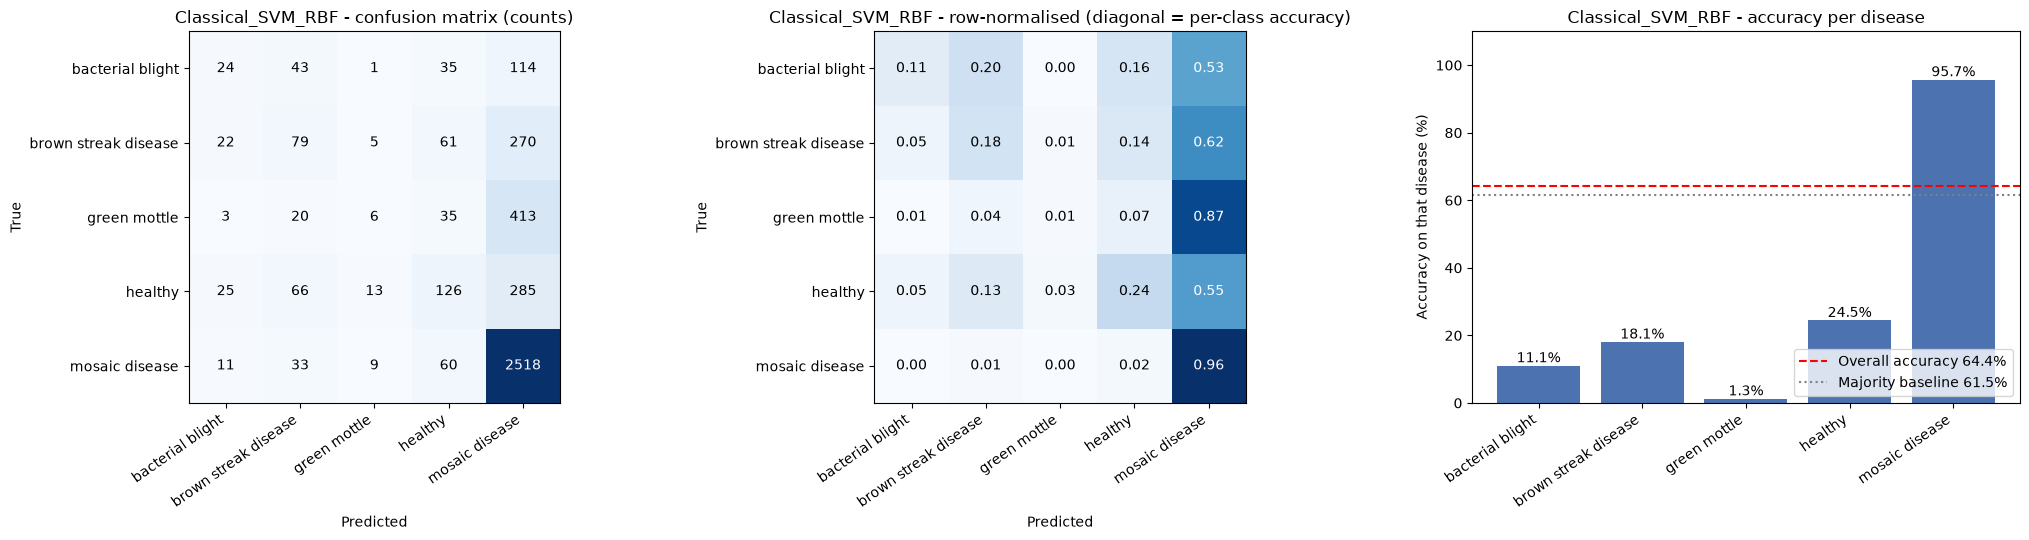

Saved model pipeline and per-image predictions for SVM_RBF
=== Classical_RandomForest on 4,277 test images ===
Accuracy: 63.36% | Macro-F1: 0.2212 | Weighted-F1: 0.5171 | Balanced accuracy: 23.89% | Loss: 1.0342
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,0,0.0%,0.0%,0.0%,mosaic disease (85% of its mages)
brown streak disease,437,28,6.4%,42.4%,11.1%,mosaic disease (86% of its mages)
green mottle,477,0,0.0%,0.0%,0.0%,mosaic disease (97% of its mages)
healthy,515,71,13.8%,48.3%,21.5%,mosaic disease (83% of its mages)
mosaic disease,2631,2611,99.2%,64.3%,78.0%,healthy (1% of its mages)


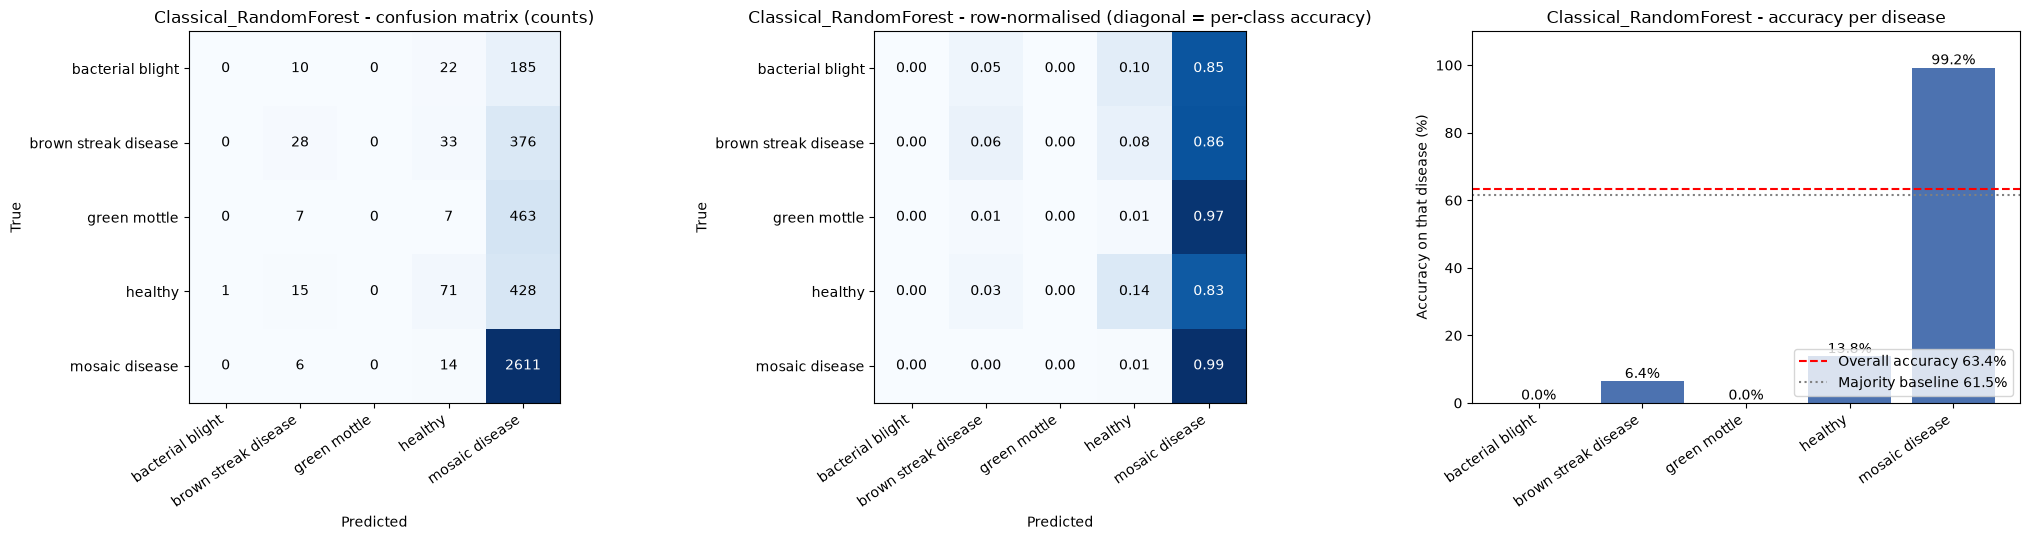

Saved model pipeline and per-image predictions for RandomForest
=== Classical_XGBoost on 4,277 test images ===
Accuracy: 65.58% | Macro-F1: 0.3062 | Weighted-F1: 0.5704 | Balanced accuracy: 29.67% | Loss: 1.0022
Majority-class baseline: 61.52%  (accuracy alone flatters imbalanced data - judge by macro-F1 / per-class accuracy)


,Test images,Correct,Accuracy (recall),Precision,F1,Most confused with
Disease class,,,,,,
bacterial blight,217,16,7.4%,33.3%,12.1%,mosaic disease (63% of its mages)
brown streak disease,437,81,18.5%,43.5%,26.0%,mosaic disease (66% of its mages)
green mottle,477,11,2.3%,30.6%,4.3%,mosaic disease (90% of its mages)
healthy,515,113,21.9%,47.3%,30.0%,mosaic disease (64% of its mages)
mosaic disease,2631,2584,98.2%,68.6%,80.8%,healthy (1% of its mages)


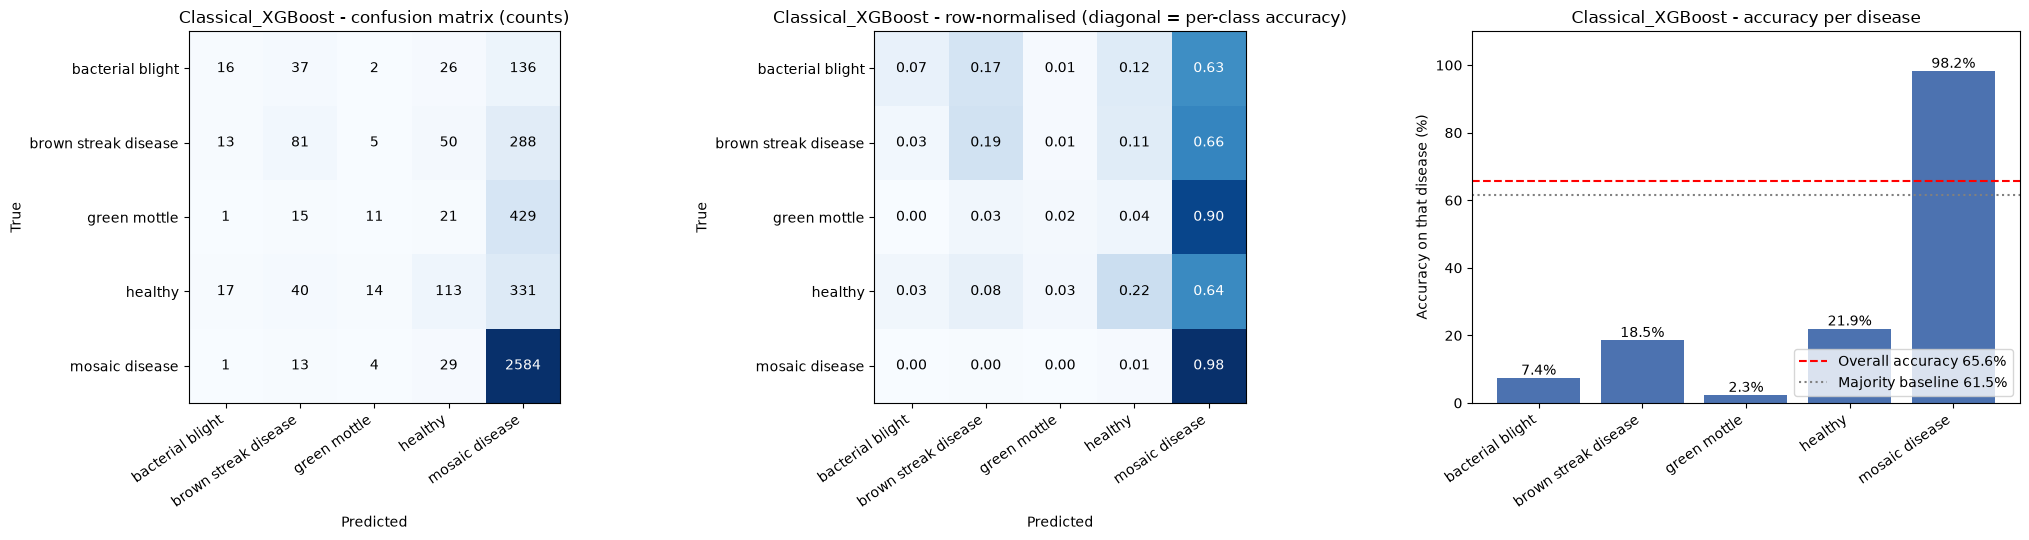

Saved model pipeline and per-image predictions for XGBoost


In [24]:
# Refit chosen hyperparameters on train+validation, then evaluate test exactly once.
# Saved the fitted pipeline for reproducibility. Measure model-only inference latency.
# seperately from feature extraction latency.
import joblib

final_rows = []
trainval_idx = np.concatenate([train_idx, val_idx])
with open(os.path.join(CLASSICAL_RESULTS_DIR, "best_configs.json")) as f:
    best_configs_f = json.load(f)

for model_name, param in best_configs_f.items():
    final_model = make_classical_model(model_name, param)
    t0_train = time.perf_counter()
    final_model.fit(X[trainval_idx], y[trainval_idx])
    final_fit_seconds = time.perf_counter() - t0_train

    t0_test = time.perf_counter()
    test_pred = final_model.predict(X[test_idx])
    inference_seconds = time.perf_counter() - t0_test
    y_prob = None
    if hasattr(final_model, "predict_proba"):
        y_prob = final_model.predict_proba(X[test_idx])
        # Align probability columns with class indices if a class is absent during fit.
        estimator_classes = final_model.named_steps["model"].classes_
        if not np.array_equal(estimator_classes, np.arange(n_classes)):
            aligned = np.zeros((len(test_idx), n_classes), dtype=np.float64)
            aligned[:, estimator_classes.astype(int)] = y_prob
            y_prob = aligned

        test_manifest = manifest.iloc[test_idx].reset_index(drop=True)
        prediction_out = test_manifest[["filepath", "class_index", "class_name"]].copy()
        prediction_out = prediction_out.rename(columns={
            "class_index": "true_class_index", "class_name": "true_class"
        })
        prediction_out["prediction_class_index"] = test_pred
        prediction_out["predicted_class"] = [class_names[int(i)] for i in test_pred]
        prediction_out["correct"] = test_pred == y[test_idx]
        if y_prob is not None:
            prediction_out["confidence"] = y_prob.max(axis=1) 
            for class_idx, class_name in enumerate(class_names):
                safe_name = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in class_name)
                prediction_out[f"prob_{safe_name}"] = y_prob[:, class_idx]  
        prediction_out.to_csv(
            os.path.join(CLASSICAL_RESULTS_DIR, f"{model_name}_test_prediction.csv"), index=False
        )       
        joblib.dump(final_model, os.path.join(CLASSICAL_DIR, f"{model_name}.joblib"))

        result = evaluate_predictions(
            y[test_idx], test_pred, f"Classical_{model_name}", y_prob=y_prob, params=None, show_plots=True
        )
        final_rows.append({
            "model": model_name, 
            "selected_params": json.dumps(param, sort_keys=True), "validation_macro_f1": float(tuning_df.loc[tuning_df["model"] == model_name, "validation_macro_f1"].max()),
            "test_accuracy": result["accuracy"],
            "test_macro_f1": result["macro_f1"],
            "test_balanced_accuracy": result["balanced_accuracy"],
            "final_fit_seconds_trainval": final_fit_seconds,
            "test_predict_seconds": inference_seconds,
            "test_ms_per_image_model_only": 1000 * inference_seconds / len(test_idx),
            "feature_extraction_median_seconds_per_image": (
                float(extraction_times["feature_extraction_seconds"].dropna().median()) if extraction_times["feature_extraction_seconds"].notna().any() else np.nan
            ),
        })
        print(f"Saved model pipeline and per-image predictions for {model_name}")

In [ ]:
final_df = pd.DataFrame(final_rows)
final_df.to_csv(os.path.join(CLASSICAL_RESULTS_DIR, "final_test_summary.csv"), index=False)
display(final_df)
print(f"Classical artifacts saved under: {CLASSICAL_DIR}/")

### Final analysis: Paired bootstrap intervals and McNemar tests
This cell does no training. It reads the saved per-image prediction CSVs, normalises the CNN/classical prediction-column names, joins rows by **filepath**, computes percentile bootstrap 95% intervals for accuracy and macro-F1, and runs exact McNemar tests for paired model comparisons. It uses the same test images for each comparison and applies Holm correction to the family of McNemar p-values.

In [1]:
import os, glob, json, itertools, warnings
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import binomtest

PREDICTION_FILES = glob.glob("artifacts/predictions/*_test_predictions.csv")
PREDICTION_FILES += glob.glob("artifacts/classical/results/*_test_prediction.csv")
if not PREDICTION_FILES:
    raise FileNotFoundError("No prediction CSVs found. Run the CNN/classical prediction cells first.")

def _normalise_prediction_csv(path):
    df = pd.read_csv(path)
    # Accomodate both historical spellings.
    pred_col = next((c for c in ("predicted_class_index", "prediction_class_index") if c in df.columns), None)
    true_col = next((c for c in ("true_class_index", "class_index") if c in df.columns), None)
    if "filepath" not in df or pred_col is None or true_col is None:
        raise ValueError(f"{path} needs filepath, a true-label column and a predicted-index column.")
    out = df[["filepath", true_col, pred_col]].copy()
    out.columns = ["filepath", "y_true", "y_pred"]
    out["filepath"] = out["filepath"].astype(str).map(os.path.abspath)
    out["y_true"] = out["y_true"].astype(int) 
    out["y_pred"] = out["y_pred"].astype(int)
    out = out.drop_duplicates("filepath")
    if "_test_predictions.csv" in os.path.basename(path):
        model = os.path.basename(path).replace("_test_predictions.csv", "")
    else:
        model = os.path.basename(path).replace("_test_prediction.csv", "")
    return model, out

predictions = {}
for path in sorted(set(PREDICTION_FILES)):
    try:
        name, frame = _normalise_prediction_csv(path)
        predictions[name] = frame
    except Exception as exc:
        warnings.warn(f"Skipping {path}: {exc}")

if len(predictions) < 2:
    raise ValueError(f"Need at least two usable predictions CSVs; found {list(predictions)}")

def bootstrap_metrics(y_true, y_pred, n_boot=2000, seed=42):
    """Percentile bootstrap over test images; macro-F1 recomputes all class per resample"""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    acc_samples = np.empty(n_boot)
    f1_samples = np.empty(n_boot)
    labels = np.unique(np.concatenate([y_true, y_pred]))
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        acc_samples[b] = accuracy_score(y_true[idx], y_pred[idx])
        f1_samples[b] = f1_score(y_true[idx], y_pred[idx], labels=labels, average="macro", zero_division=0)
    return {
        "n_test": n,
        "accuracy": accuracy_score(y_true, y_pred),
        "accuracy_ci_low": np.quantile(acc_samples, 0.025),
        "accuracy_ci_high": np.quantile(acc_samples, 0.975),
        "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
        "macro_f1_ci_low": np.quantile(f1_samples, 0.025),
        "macro_f1_ci_high": np.quantile(f1_samples, 0.975),       
    }

stats_rows = []
for model, frame in predictions.items():
    stats = bootstrap_metrics(frame["y_true"], frame["y_pred"], seed=42)
    stats_rows.append({"model": model, **stats})
stats_df = pd.DataFrame(stats_rows).sort_values("macro_f1", ascending=False)
os.makedirs("results", exist_ok=True)
stats_df.to_csv("results/bootstrap_test_intervals.csv", index=False)
display(stats_df.style.format({
    "accuracy": "{:.4f}", "accuracy_ci_low": "{:.4f}", "accuracy_ci_high": "{:.4f}",
    "macro_f1": "{:.4f}", "macro_f1_ci_low": "{:.4f}", "macro_f1_ci_high": "{:.4f}",       
}))

# Main planned comparisons. Use name matches but only compare models that exist.format
available = list(predictions)
def _find_model(fragment):
    return next((name for name in available if fragment.lower() in name.lower()), None)

main_pairs = [
    (_find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0"),
     _find_model("ResNet50")),
    (_find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0"),
     _find_model("MobileNetV2")),
    (_find_model("EfficientNetB0_weighted"),
     _find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0")),
    (_find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0"),
     _find_model("SVM_RBF")),
    (_find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0"),
     _find_model("RandomForest")),
    (_find_model("EfficientNetB0_unweighted") or _find_model("EfficientNetB0"),
     _find_model("XGBoost")),
]
main_pairs = [(a,b) for a,b in main_pairs if a and b and a != b]
# Remove duplicate ordered pairs
main_pairs = list(dict.fromkeys(tuple(sorted(pair)) for pair in main_pairs))

mcnemar_rows = []
for model_a, model_b in main_pairs:
    a = predictions[model_a].rename(columns={"y_true":"true_a", "y_pred":"pred_a"})
    b = predictions[model_b].rename(columns={"y_true":"true_b", "y_pred":"pred_b"})
    joined = a.merge(b[["filepath", "true_b", "pred_b"]], on="filepath", how="inner", validate="one_to_one")
    joined = joined[joined["true_a"] == joined["true_b"]]
    if len(joined) == 0:
        continue
    correct_a = joined["pred_a"].to_numpy() == joined["true_a"].to_numpy()
    correct_b = joined["pred_b"].to_numpy() == joined["true_b"].to_numpy()
    b_only = int(np.sum(correct_a & ~correct_b)) # A correct, B wrong
    c_only = int(np.sum(~correct_a & correct_b)) # B correct, A wrong
    discordant = b_only + c_only
    p_value = float(binomtest(min(b_only, c_only), discordant, 0.5, alternative="two-sided").pvalue) if discordant else 1.0
    mcnemar_rows.append({
        "model_a": model_a, "model_b": model_b, "n_joined": len(joined),
        "a_correct_b_wrong": b_only, "a_wrong_b_correct": c_only,
        "discordant_pairs": discordant, "mcnemar_exact_p": p_value,
    })

mcnemar_df = pd.DataFrame(mcnemar_rows)
if not mcnemar_df.empty:
    # Holm step-down family-wise correction, without extra dependencies.
    order = np.argsort(mcnemar_df["mcnemar_exact_p"].to_numpy())
    pvals = mcnemar_df["mcnemar_exact_p"].to_numpy()
    adjusted = np.empty_like(pvals)
    running = 0.0
    m = len(pvals)
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m-rank) * pvals[idx]))
        adjusted[idx] = running
    mcnemar_df["mcnemar_holm_p"] = adjusted
    mcnemar_df.to_csv("results/mcnemar_paired_tests.csv", index=False)

display(mcnemar_df)
print("Saved results/bootstrap_test_intervals.csv and results/mcnemar_paired_tests.csv")

,model,n_test,accuracy,accuracy_ci_low,accuracy_ci_high,macro_f1,macro_f1_ci_low,macro_f1_ci_high
3,EfficientNetB0,4277,0.7982,0.7861,0.8099,0.6579,0.6384,0.6771
6,ResNet50,4277,0.7928,0.7805,0.8050,0.6389,0.6176,0.6589
5,MobileNetV2,4277,0.7734,0.7610,0.7858,0.6213,0.6004,0.6412
4,EfficientNetB0_weighted,4277,0.6979,0.6844,0.7112,0.6009,0.5838,0.6191
2,XGBoost,4277,0.6558,0.6420,0.6701,0.3062,0.2889,0.3236
1,SVM_RBF,4277,0.6437,0.6294,0.6579,0.3053,0.2877,0.3218
0,RandomForest,4277,0.6336,0.6194,0.6481,0.2212,0.2093,0.2326


,model_a,model_b,n_joined,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,mcnemar_exact_p,mcnemar_holm_p
0,EfficientNetB0,ResNet50,4277,287,264,551,3.486485e-01,3.486485e-01
1,EfficientNetB0,MobileNetV2,4277,321,215,536,5.382396e-06,1.076479e-05
2,EfficientNetB0,EfficientNetB0_weighted,4277,592,163,755,5.738512e-58,1.721553e-57
3,EfficientNetB0,SVM_RBF,4277,878,217,1095,1.083996e-94,5.419981e-94
4,EfficientNetB0,RandomForest,4277,923,219,1142,3.427911e-103,2.056747e-102
5,EfficientNetB0,XGBoost,4277,825,216,1041,2.476485e-84,9.905941e-84


Saved results/bootstrap_test_intervals.csv and results/mcnemar_paired_tests.csv


### Grad-CAM examples (best saved checkpoint)
This cell selects up to six test images from EfficientNetB0 predictions: correct examples first, then bacterial-blight images misclassified as healthy where available. It displays the Grad-CAM maps for EfficientNetB0 and any other CNN checkpoints that exist. The first map differentiates the last convolutional feature map; the second differentiates the backbone's final spatial feature map; with gradients flowing through the classifier head. These are explanatory visualizations, not additional evaluations.

In [ ]:
import os, glob, warnings
import pandas as pd


PRED_DIR = "artifacts/predictions"
GRADCAM_DIR = "artifacts/gradcam"
os.makedirs(GRADCAM_DIR, exist_ok=True)
eff_u_pred_path = os.path.join(PRED_DIR, "EfficientNetB0_test_predictions.csv")
if not os.path.isfile(eff_u_pred_path):
    raise FileNotFoundError(f"Missing {eff_u_pred_path}. Run the checkpoint prediction cells first.")

eff_u_pred = pd.read_csv(eff_u_pred_path)
pred_col = next(c for c in ("predicted_class_index", "prediction_class_index") if c in eff_u_pred.columns)
true_col = next(c for c in ("true_class_index", "class_index") if c in eff_u_pred.columns)

def _norm_class(x):
    return str(x).lower().replace("Cassava___ ", "").replace("-", "_").replace(" ", "_")

healthy_idx = next((i for i, c in enumerate(class_names) if "healthy" in _norm_class(c)), None)
bacterial_idx = next((i for i, c in enumerate(class_names) if "bacterial_blight" in _norm_class(c)), None)
eff_u_pred["filepath"] = eff_u_pred["filepath"].astype(str)
eff_u_pred["correct"] = eff_u_pred[pred_col].astype(int) == eff_u_pred[true_col].astype(int)
selected = []
# Up to 3 correct examples, preferring diverse true classes.
correct_rows = eff_u_pred[eff_u_pred["correct"]].drop_duplicates("true_class_index")
selected.extend(correct_rows.head(3).to_dict("records"))
if bacterial_idx is not None and healthy_idx is not None:
    confusions = eff_u_pred[
        (eff_u_pred[true_col].astype(int) == bacterial_idx) &
        (eff_u_pred[pred_col].astype(int) == healthy_idx)
    ]
    selected.extend(confusions.head(3).to_dict("records"))
if len(selected) < 6:
    already = {r["filepath"] for r in selected}
    remaining = eff_u_pred[~eff_u_pred["filepath"].isin(already)]
    selected.extend(remaining.head(6-len(selected)).to_dict("records"))
selected = selected[:6]
if not selected:
    raise ValueError("No images were selected for Grad-CAM visualization.")
